# Searching for a hidden algorithm switch in code models (DAS, iteration 8)

When a code model solves *"count the connected components of a graph"*, it picks an algorithm: BFS, DFS or union-find. **Claim K2** asks whether there is a **low-rank causal variable** for that choice inside the model, a linear subspace that *is* the algorithm decision. The alternative is that there is only a **steering handle**: a direction that changes what the model writes without being the model's own variable.

The artifact tests K2 with **one distributed-alignment-search (DAS) protocol**. The protocol was hash-committed before any GPU use (commit #0):

| piece | definition |
|---|---|
| map class | linear orthonormal `R` (d_model x 8, nested ranks k = 1/2/4/8) |
| interchange | `h <- h + R (Rᵀ h_src − Rᵀ h_base)` on the block-L output at the decision position `d` |
| objective | bounded, CDAS-style: KL from the source's own class distribution to the edited base's |
| readout | class margin `log P(c_src) − log P(c_base)` at `d`; `Delta = margin_edit − margin_base` |
| recovery | `mean(Delta_DAS) / mean(Delta_FULL)` over held-out pairs with abs(Delta_FULL) >= 1 nat (FULL = exchange the whole state) |

The protocol runs at three sites: the Qwen3-8B T10 decision token (`def solve(n, edges):` + indent + ` def`, then the helper name: ` bfs` / ` dfs` / ` find`), the gemma-3-4b-it grid-path decision token, and the Qwen3-8B task band (blocks 12-23). Seven controls with thresholds were committed before any fit: c1 random subspaces, c2 label controls, c3 random-init network, c4 reverse, c5 natural-PC retention, c6 natural-variance share and c7 seed stability.

**Result of the full run: K2 DISCONFIRMED (p_K2 = 0.037).** Both decision sites carry a strong rank-4 steering handle. For example, the T10 edit makes Qwen3-8B write 29/30 correct DFS programs where it otherwise writes union-find. But maps fitted to *wrong* labels (c2) keep 11-87% of the effect (committed limit 10%), and maps fitted on an *untrained* copy of the network (c3) keep 41-69% (limit 25%). The edit also overshoots the full-state exchange 3-8x (OFF-MANIFOLD).

### What this notebook runs (CPU only, about a minute, no model download)
1. **The DAS machinery** (`src/engine8.py`, `src/das8.py`, `src/stats8.py`, copied as-is) and the artifact's own **CPU equivalence test** (`tests/test_cpu_tiny.py`) on tiny random-weight Qwen3 / Gemma3 models. The decision-site KV path and the band recompute path must reproduce full recomputation.
2. **The real Qwen3-8B results**: 100 of the 600 held-out teacher-forced pairs at the T10 decision site (block L* = 22), from `full_method_out.json`. On these the notebook computes normalised recovery by rank with the two-way cluster bootstrap, the k* rule, the OFF-MANIFOLD flag and per-class recovery. It also recomputes the **seed-stability control c7 from the three real fitted maps**.
3. **The verdict and K2 rules** (`src/analysis8.py`), applied to the stored per-site control and generation results, plus an exact re-derivation of the McNemar p-values (`audit/rederive.py`).
4. **Figures**: per-pair effects, recovery by rank, block scan, c7 geometry, specificity controls and generation.

**Not run here:** the GPU stages of `method.py`, which take about 3.5 GPU-hours on one 23 GB L4 with Qwen3-8B and gemma-3-4b-it in bf16. They cover token maps, state caches, scans, fits, label-control refits, random-init networks, generation scored by hidden tests, and mediation. This notebook reads their stored outputs.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (version pinned in the artifact's pyproject.toml)
_pip('loguru==0.7.3')

# torch, numpy, scipy, matplotlib, transformers — pre-installed on Colab, install locally only (Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('torch==2.9.0+cpu', '--index-url', 'https://download.pytorch.org/whl/cpu')
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0',
         'transformers==5.0.0', 'huggingface_hub==1.4.0', 'tokenizers==0.22.2')

In [2]:
from __future__ import annotations

# ---- original imports (src/cfg8.py, src/engine8.py, src/das8.py, src/stats8.py, src/analysis8.py, tests/test_cpu_tiny.py)
import gc
import json
import math
import time
from contextlib import contextmanager
from typing import Any, Callable, Iterator

import numpy as np
import torch
from loguru import logger
from scipy import stats

# ---- notebook additions
import sys
import types
import warnings

import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", message="Converting a tensor with requires_grad=True")  # das8.fit logs float(loss)
logger.remove()   # as cfg8.setup_logging, but stdout only (the original also writes logs/<stage>.log)
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
T0_NOTEBOOK = time.time()
print("torch", torch.__version__, "| numpy", np.__version__)

torch 2.9.0+cpu | numpy 2.0.2


In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-8/experiment-40/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
# notebook: an older demo version of mini_demo_data.json (another layout) can still sit at the GitHub URL until this
# folder is republished; when the remote copy lacks this notebook's fields, use the local file
if "das_maps" not in data and Path("mini_demo_data.json").exists():
    print("GitHub copy has an older layout; using local mini_demo_data.json")
    data = json.loads(Path("mini_demo_data.json").read_text())
print(data["metadata"]["description"])
print("dataset:", data["datasets"][0]["dataset"], "|", len(data["datasets"][0]["examples"]), "of",
      data["metadata"]["n_examples_full_dataset"], "held-out pairs")
print("fitted maps:", list(data["das_maps"]))
print("stored summaries:", list(data["metadata"]["reported"]))

GitHub copy has an older layout; using local mini_demo_data.json
Demo subset of art_e-_q5mSJGrSb (iteration 8: one DAS protocol with seven controls). Dataset = 100 of the 600 held-out teacher-forced pairs at the Qwen3-8B T10 decision site (block L* = 22); das_maps = the three fitted seed maps there; reported = the stored per-site summaries computed by the full GPU run.
dataset: T10_dec_teacher_forced | 100 of 600 held-out pairs
fitted maps: ['T10_dec_L22_seed0', 'T10_dec_L22_seed1', 'T10_dec_L22_seed2']
stored summaries: ['dec_T10', 'band_T10', 'dec_GRID', 'dec_T10_L24', 'rinit_T10', 'rinit_T10_band', 'rinit_GRID', 'rinit_T10_L24', 'gen_T10_dec', 'gen_T10_band', 'gen_GRID_dec', 'post_T10', 'scan_T10', 'scan_GRID', 'verdicts', 'K2', 'unit_tests_cpu']


## Configuration

The first block holds the **protocol constants** from `src/cfg8.py`. They were fixed in `predictions/commit0.json` before any fit, so leave them unchanged to reproduce the paper. The second block holds the **demo-scale knobs** that this notebook adds; each comment gives the artifact's own value. Every knob costs at most a few seconds on CPU, even at the original values.

In [5]:
# ===== protocol constants (src/cfg8.py; committed in predictions/commit0.json before any GPU use) =====
FAMILY = {
    "qwen": {"id": "Qwen/Qwen3-8B", "rev": "b968826d9c46dd6066d109eabc6255188de91218", "n_layers": 36, "d_model": 4096,
             "n_kv": 8, "head_dim": 128, "band": tuple(range(12, 24)), "stop_ids": (151645, 151643)},
    "gemma": {"id": "google/gemma-3-4b-it", "rev": "093f9f388b31de276ce2de164bdc2081324b9767", "n_layers": 34,
              "d_model": 2560, "n_kv": 4, "head_dim": 256, "band": tuple(range(11, 23)), "stop_ids": (1, 106)},
}
UNITS = {
    "T10": {"family": "qwen", "task": "T10", "default": "union_find", "classes": ["bfs", "dfs", "union_find"],
            "primary": "dfs", "max_new": 512, "fence": "bench"},
    "GRID": {"family": "gemma", "task": "T1", "default": None, "classes": ["bfs", "dfs"], "primary": "bfs",
             "max_new": 1024, "fence": "path"},
}
RANKS = (1, 2, 4, 8)
K_MAX = 8
FIT_STEPS = 240              # used by the GPU fits (DecSite.fit default); scan fits use SCAN_STEPS
SCAN_STEPS = 100
LR = 2e-2
VAL_EVERY = 20
PATIENCE = 3
N_RANDOM_SUBSPACES = 50      # c1: Haar subspaces per rank
RANDOM_SEED0 = 7000
LABEL_CONTROL_SEEDS = (10, 11, 12)
FIT_SEEDS = (0, 1, 2)
OFF_MANIFOLD = 1.5           # held-out recovery above this = the edit overshoots the full-state exchange
TRAIN_PAIR_CAP = 2000
HELD_PAIR_CAP = 600
THRESH = {"c1_median_max": 0.05, "c2_ratio_max": 0.10, "c3_ratio_max": 0.25, "c4_min": 0.5, "c5_min": 0.5,
          "c6_pct": 95.0, "c7_cos_min": 0.5, "c7_pct": 99.0, "V0_tf": 0.5, "V0_tf_lo": 0.25, "V0_gen": 0.5,
          "V0_pass_ratio": 0.8, "V0_mcnemar_p": 0.05}

# ===== demo-scale knobs (all at the artifact's own values; the whole notebook computes in ~5 s on 2 CPU cores) =====
# minimal smoke-test values: ("qwen",), 20, 50, 20
TINY_FAMILIES = ("qwen", "gemma")   # tiny random-weight models for the CPU equivalence test  (original: ("qwen", "gemma"))
N_PAIRS_DEMO = 100                # held-out T10 pairs analysed, max 100 in mini_demo_data  (full run: 600 in full_method_out)
N_BOOT = 2000                     # two-way cluster bootstrap resamples for recovery CIs   (original: N_BOOT = 2000)
N_RANDOM_C7 = 1000                # random subspace pairs for the c7 reference percentile  (original: 1000)

## How `method.py` is organised, and what this notebook takes from it

`method.py` is a resumable stage runner. Each stage is a script that skips work whose result file already exists, and the GPU stages load one model at a time:

| stage | script | needs | in this notebook |
|---|---|---|---|
| S0 / S1 / #0 | `s0_inputs.py`, `prompts8.py`, `commit0.py` | CPU | — (inputs, prompt sets, hash-chained commitment) |
| S3-S6 decision site | `run_dec.py --unit T10 / GRID` | GPU, Qwen3-8B / gemma-3-4b-it | **machinery** (`engine8`, `das8`) on tiny models; **recovery, k\*, c7** on the stored rows and maps |
| S7 task band | `run_band.py` | GPU | `BandSite` code + its equivalence test |
| S8 random-init (c3) | `run_rinit.py` | GPU | stored result feeds the verdict |
| S9 generation | `run_gen.py`, `label8.py` | GPU + hidden tests | stored tables feed the verdict |
| S10 mediation | `run_med.py` | GPU | — |
| analysis | `analysis8.py` | CPU | **verdict + K2 rules** |
| figures / audit | `figures8.py`, `audit/rederive.py` | CPU | figures; exact McNemar and recovery re-derivation |

Run in this order, the cells below follow the code path of one decision-site measurement: statistics → engine → DAS protocol → equivalence test → real rows → verdicts.

## 1. Statistics (`src/stats8.py`, unchanged)

- **`recovery`** is the headline estimator: `mean(Delta_edit) / mean(Delta_full)` over pairs where the full-state exchange moves the margin by at least 1 nat. Its 95% CI comes from a **two-way cluster bootstrap**, which resamples source prompts and base prompts independently. A pair enters with multiplicity `count_src x count_base`, so the CI respects that each prompt appears in many pairs.
- **`mcnemar`** is the exact test on CRN-paired generation outcomes (DAS vs RAND on the same random stream).
- **`cluster_wilcoxon_p`** is the one-sided pair-level test behind p_c2 and p_c3.
- **`wilson`** gives the intervals on generation shares.

In [6]:
"""Statistics: normalised recovery with a two-way cluster bootstrap (source prompts x base prompts), Wilson
intervals, exact McNemar on CRN-paired outcomes, one-sided Wilcoxon, Spearman with permutation p."""


def recovery(d_edit: np.ndarray, d_full: np.ndarray, src: list[str], base: list[str], n_boot: int = 2000,
             seed: int = 0, min_full: float = 1.0) -> dict[str, Any]:
    """recovery = mean(Delta_edit) / mean(Delta_full) over pairs with |Delta_full| >= min_full; CI by resampling
    source and base prompts independently (a pair enters with multiplicity count_src x count_base)."""
    d_edit = np.asarray(d_edit, float)
    d_full = np.asarray(d_full, float)
    ok = np.abs(d_full) >= min_full
    if ok.sum() == 0:
        return {"n": 0, "recovery": None}
    de, df = d_edit[ok], d_full[ok]
    s = np.array(src)[ok]
    b = np.array(base)[ok]
    us, ub = np.unique(s), np.unique(b)
    si = np.searchsorted(us, s)
    bi = np.searchsorted(ub, b)
    point = float(de.mean() / df.mean())
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        cs = np.bincount(rng.integers(0, len(us), len(us)), minlength=len(us))
        cb = np.bincount(rng.integers(0, len(ub), len(ub)), minlength=len(ub))
        w = cs[si] * cb[bi]
        if w.sum() == 0 or (w * df).sum() == 0:
            continue
        boots.append(float((w * de).sum() / (w * df).sum()))
    lo, hi = (float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))) if boots else (None, None)
    return {"n": int(ok.sum()), "n_src": int(len(us)), "n_base": int(len(ub)), "recovery": point, "ci95": [lo, hi],
            "mean_delta_edit": float(de.mean()), "mean_delta_full": float(df.mean()),
            "iia_like_share_positive": float(np.mean(de > 0))}


def ratio_ci(num: np.ndarray, den_mean: float, src: list[str], base: list[str], n_boot: int = 2000, seed: int = 0
             ) -> dict[str, Any]:
    """mean(num) / den_mean with a two-way cluster bootstrap of the numerator (denominator held fixed)."""
    num = np.asarray(num, float)
    s, b = np.array(src), np.array(base)
    us, ub = np.unique(s), np.unique(b)
    si, bi = np.searchsorted(us, s), np.searchsorted(ub, b)
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        cs = np.bincount(rng.integers(0, len(us), len(us)), minlength=len(us))
        cb = np.bincount(rng.integers(0, len(ub), len(ub)), minlength=len(ub))
        w = cs[si] * cb[bi]
        if w.sum():
            boots.append(float((w * num).sum() / w.sum() / den_mean))
    return {"ratio": float(num.mean() / den_mean) if den_mean else None,
            "ci95": [float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))] if boots else None}


def wilson(k: int, n: int, z: float = 1.96) -> list[float | None]:
    if n == 0:
        return [None, None]
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return [max(0.0, c - h), min(1.0, c + h)]


def mcnemar(a: list[bool], b: list[bool]) -> dict[str, Any]:
    """Exact two-sided McNemar on paired booleans (a vs b): discordant counts and p."""
    n10 = sum(1 for x, y in zip(a, b) if x and not y)
    n01 = sum(1 for x, y in zip(a, b) if y and not x)
    n = n10 + n01
    p = float(stats.binomtest(n10, n, 0.5).pvalue) if n else 1.0
    p1 = float(stats.binomtest(n10, n, 0.5, alternative="greater").pvalue) if n else 1.0
    return {"a_only": n10, "b_only": n01, "p_two_sided": p, "p_one_sided_a_gt_b": p1}


def wilcoxon_greater(x: np.ndarray, y: np.ndarray) -> float:
    d = np.asarray(x, float) - np.asarray(y, float)
    d = d[d != 0]
    if d.size < 3:
        return 1.0
    return float(stats.wilcoxon(d, alternative="greater").pvalue)


def cluster_wilcoxon_p(x: np.ndarray, y: np.ndarray, src: list[str], base: list[str], n_boot: int = 2000,
                       seed: int = 0) -> dict[str, Any]:
    """One-sided pair-level test of mean(x - y) > 0 with a two-way cluster bootstrap (p = share of resamples <= 0)."""
    d = np.asarray(x, float) - np.asarray(y, float)
    s, b = np.array(src), np.array(base)
    us, ub = np.unique(s), np.unique(b)
    si, bi = np.searchsorted(us, s), np.searchsorted(ub, b)
    rng = np.random.default_rng(seed)
    ms = []
    for _ in range(n_boot):
        cs = np.bincount(rng.integers(0, len(us), len(us)), minlength=len(us))
        cb = np.bincount(rng.integers(0, len(ub), len(ub)), minlength=len(ub))
        w = cs[si] * cb[bi]
        if w.sum():
            ms.append(float((w * d).sum() / w.sum()))
    ms = np.array(ms)
    return {"mean_diff": float(d.mean()), "p_cluster_boot": float((np.sum(ms <= 0) + 1) / (len(ms) + 1)),
            "p_wilcoxon_pairs": wilcoxon_greater(x, y)}


def spearman_perm(x: np.ndarray, y: np.ndarray, n_perm: int = 10000, seed: int = 0) -> dict[str, Any]:
    x, y = np.asarray(x, float), np.asarray(y, float)
    if len(x) < 4:
        return {"rho": None, "p_one_sided": None, "n": int(len(x))}
    rho = float(stats.spearmanr(x, y).statistic)
    rng = np.random.default_rng(seed)
    cnt = 0
    for _ in range(n_perm):
        r = stats.spearmanr(x, rng.permutation(y)).statistic
        if r >= rho:
            cnt += 1
    return {"rho": rho, "p_one_sided": (cnt + 1) / (n_perm + 1), "n": int(len(x))}


def partial_spearman(x: np.ndarray, y: np.ndarray, z: np.ndarray) -> float | None:
    """Spearman partial correlation of x and y controlling z (rank-residual method)."""
    if len(x) < 5:
        return None
    rx, ry, rz = (stats.rankdata(v) for v in (x, y, z))
    A = np.vstack([rz, np.ones_like(rz)]).T
    ex = rx - A @ np.linalg.lstsq(A, rx, rcond=None)[0]
    ey = ry - A @ np.linalg.lstsq(A, ry, rcond=None)[0]
    den = np.sqrt((ex ** 2).sum() * (ey ** 2).sum())
    return float((ex * ey).sum() / den) if den else None


# notebook: the other modules call these as `ST.<name>` (`import stats8 as ST`)
ST = types.SimpleNamespace(recovery=recovery, ratio_ci=ratio_ci, wilson=wilson, mcnemar=mcnemar,
                           wilcoxon_greater=wilcoxon_greater, cluster_wilcoxon_p=cluster_wilcoxon_p,
                           spearman_perm=spearman_perm, partial_spearman=partial_spearman)

## 2. Model engine (`src/engine8.py`, the parts the DAS machinery uses)

One adapter serves both families:

- **`LM`** exposes `embed`, `rope`, `block(l, ...)` and `final`, so the DAS code can run *part* of the network.
- **`prefill`** is a batch-1 prompt pass. It can apply edits to block **outputs** through forward hooks, and it returns the KV cache.
- **`states_at`** gives teacher-forced block outputs of every block at the last position, plus the logits there.
- **`KVFeed`** is a duck-typed, never-mutated cache. It lets blocks `L+1..N-1` run for the decision position alone, against the base prompt's cached keys and values.

**Naming convention.** BLOCK `l` means decoder block `l` (0-based). Its output is HF `hidden_states[l + 1]`, and every edit replaces a block output.

**Left out.** `load_lm` puts the 8B / 4B checkpoints on a CUDA device (Qwen keeps its embedding table on the CPU to leave room for KV caches). The CRN sampler `decode` drives generation with one uniform per (row, step) and a fence stop. Neither can run here; both are in `src/engine8.py`.

**One notebook compat fix.** In transformers 5.x, Gemma3 has a single rotary module keyed by layer type, where 4.57 (the artifact's pin) had `rotary_emb` and `rotary_emb_local`. The two lines marked `notebook compat` pick the right embeddings per layer. Qwen's path is unchanged.

In [7]:
class LM:
    """Thin adapter over a HF causal LM: the pieces the DAS machinery needs, identical for both families."""

    def __init__(self, family: str, tok: Any, model: Any, info: dict[str, Any]):
        self.family = family
        self.tok = tok
        self.model = model
        self.info = info
        self.mm = model.model
        self.layers = self.mm.layers
        self.N = len(self.layers)
        self.D = FAMILY[family]["d_model"]
        self.dev = model.lm_head.weight.device
        self.stop_ids = FAMILY[family]["stop_ids"]
        cap = getattr(model.config, "final_logit_softcapping", None)
        self.softcap = cap

    # -------------------------------------------------------------------------------------------- pieces
    def embed(self, ids: torch.Tensor) -> torch.Tensor:
        return self.mm.embed_tokens(ids)

    def rope(self, h: torch.Tensor, pos: torch.Tensor) -> dict[str, Any]:
        if self.family == "qwen":
            return {"position_embeddings": self.mm.rotary_emb(h, pos)}
        if not hasattr(self.mm, "rotary_emb_local"):  # notebook compat: transformers 5.x Gemma3 (one module per layer type)
            return {"by_layer_type": {t: self.mm.rotary_emb(h, pos, t) for t in set(self.mm.config.layer_types)}}
        return {"position_embeddings_global": self.mm.rotary_emb(h, pos),
                "position_embeddings_local": self.mm.rotary_emb_local(h, pos)}

    def block(self, l: int, h: torch.Tensor, pos: torch.Tensor, rope: dict[str, Any], feed: Any = None,
              mask: torch.Tensor | None = None, cache_position: torch.Tensor | None = None) -> torch.Tensor:
        if "by_layer_type" in rope:  # notebook compat: transformers 5.x Gemma3 takes this layer's embeddings only
            rope = {"position_embeddings": rope["by_layer_type"][self.layers[l].attention_type]}
        out = self.layers[l](h, attention_mask=mask, position_ids=pos, past_key_values=feed,
                             use_cache=feed is not None, cache_position=cache_position, **rope)
        return out[0] if isinstance(out, tuple) else out

    def final(self, h: torch.Tensor) -> torch.Tensor:
        x = self.model.lm_head(self.mm.norm(h)).float()
        if self.softcap is not None:
            x = torch.tanh(x / self.softcap) * self.softcap
        return x

    def free(self) -> None:
        del self.model, self.mm, self.layers
        gc.collect()
        torch.cuda.empty_cache()


# ------------------------------------------------------------------------------------------------ hooks / prefill
@contextmanager
def block_hooks(lm: LM, edits: dict[int, Callable] | None = None, capture: dict[int, Callable] | None = None
                ) -> Iterator[None]:
    hs = []

    def mk(l: int):
        def hook(mod, args, out):
            h = out[0] if isinstance(out, tuple) else out
            if capture and l in capture:
                capture[l](h)
            if edits and l in edits:
                h2 = edits[l](h)
                if isinstance(out, tuple):
                    return (h2,) + tuple(out[1:])
                return h2
            return out
        return hook
    keys = set(edits or {}) | set(capture or {})
    try:
        for l in sorted(keys):
            hs.append(lm.layers[l].register_forward_hook(mk(l)))
        yield
    finally:
        for h in hs:
            h.remove()


def kv_list(cache: Any) -> list[tuple[torch.Tensor, torch.Tensor]]:
    if hasattr(cache, "layers"):
        return [(L.keys, L.values) for L in cache.layers]
    return list(zip(cache.key_cache, cache.value_cache))


@torch.no_grad()
def prefill(lm: LM, ids: list[int], edits: dict | None = None, capture: dict | None = None) -> dict[str, Any]:
    """Batch-1 prompt pass with block-output edits. Returns {'kv': [(K, V)] per block, 'logits': fp32 [V], 'P'}."""
    from transformers.cache_utils import DynamicCache

    inp = torch.tensor([ids], device=lm.dev)
    cache = DynamicCache()
    with block_hooks(lm, edits, capture):
        out = lm.mm(input_ids=inp, past_key_values=cache, use_cache=True)
    h = out.last_hidden_state[:, -1]
    logits = lm.model.lm_head(h).float()[0]
    if lm.softcap is not None:
        logits = torch.tanh(logits / lm.softcap) * lm.softcap
    kv = [(K, V) for K, V in kv_list(cache)]
    del out
    return {"kv": kv, "logits": logits, "P": len(ids)}


@torch.no_grad()
def states_at(lm: LM, ids_list: list[list[int]], blocks: list[int] | None = None) -> dict[str, Any]:
    """Teacher-forced states at the LAST position of each sequence (equal lengths batched together): block outputs
    [n, n_blocks, D] (fp32, CPU) and logits [n, V] (fp32, CPU)."""
    blocks = list(range(lm.N)) if blocks is None else blocks
    out_h = [None] * len(ids_list)
    out_l = [None] * len(ids_list)
    by_len: dict[int, list[int]] = {}
    for i, ids in enumerate(ids_list):
        by_len.setdefault(len(ids), []).append(i)
    for L, ix in by_len.items():
        for c0 in range(0, len(ix), 16):
            cix = ix[c0:c0 + 16]
            inp = torch.tensor([ids_list[i] for i in cix], device=lm.dev)
            store: dict[int, torch.Tensor] = {}

            def mk(l: int):
                def g(h: torch.Tensor) -> None:
                    store[l] = h[:, -1].float().cpu()
                return g
            with block_hooks(lm, None, {l: mk(l) for l in blocks}):
                o = lm.mm(input_ids=inp, use_cache=False)
            lg = lm.model.lm_head(o.last_hidden_state[:, -1]).float()
            if lm.softcap is not None:
                lg = torch.tanh(lg / lm.softcap) * lm.softcap
            H = torch.stack([store[l] for l in blocks], 1)
            for j, i in enumerate(cix):
                out_h[i] = H[j]
                out_l[i] = lg[j].cpu()
            del o, store
    return {"h": torch.stack(out_h), "logits": torch.stack(out_l), "blocks": blocks}


# ------------------------------------------------------------------------------------------------ KV path
class KVFeed:
    """Duck-typed cache: cat(cached K/V, new k/v) per block (autograd-safe; never mutated)."""

    def __init__(self, K: dict[int, torch.Tensor], V: dict[int, torch.Tensor]):
        self.K, self.V = K, V

    def update(self, k: torch.Tensor, v: torch.Tensor, layer_idx: int, cache_kwargs: Any = None):
        return torch.cat([self.K[layer_idx], k], 2), torch.cat([self.V[layer_idx], v], 2)

    def get_seq_length(self, layer_idx: int = 0) -> int:
        return int(next(iter(self.K.values())).shape[2])

## 3. The single DAS protocol (`src/das8.py`, unchanged)

### 3a. Class bins and geometry helpers
- **`ClassMap`** turns logits at `d` into class bins. `P(c)` is the softmax mass on the class's token set (T10 at Qwen3-8B: ` bfs` → BFS, ` dfs`/` build` → DFS, ` find`/` union` → union-find), and `P(other) = 1 − Σ P(c)`.
- **`kl`** is the bounded objective: KL from the source's own class distribution `q_src` to the edited base's.
- **`haar`** draws random orthonormal subspaces (controls c1 and c7). `principal_cosines` measures subspace overlap (c7), and `pca_basis`, `variance_share` and `project_map` implement the natural-manifold controls c5 and c6.

In [8]:
# ================================================================================================ classes
class ClassMap:
    """Class token sets at d. probs() -> [..., C + 1] (classes..., other); lp() -> log P(c) [..., C]."""

    def __init__(self, classes: list[str], token_sets: dict[str, list[int]]):
        self.classes = list(classes)
        self.sets = {c: sorted(set(int(t) for t in token_sets[c])) for c in classes}
        allt = [t for c in classes for t in self.sets[c]]
        assert len(allt) == len(set(allt)), "class token sets must be disjoint"
        self.C = len(classes)
        self._idx: dict[str, torch.Tensor] = {}

    def idx(self, c: str, dev: torch.device) -> torch.Tensor:
        k = f"{c}|{dev}"
        if k not in self._idx:
            self._idx[k] = torch.tensor(self.sets[c], device=dev, dtype=torch.long)
        return self._idx[k]

    def lp(self, logits: torch.Tensor) -> torch.Tensor:
        z = logits.float()
        lz = torch.logsumexp(z, -1, keepdim=True)
        return torch.stack([torch.logsumexp(z.index_select(-1, self.idx(c, z.device)), -1) for c in self.classes],
                           -1) - lz

    def probs(self, logits: torch.Tensor) -> torch.Tensor:
        p = self.lp(logits).exp()
        other = (1 - p.sum(-1, keepdim=True)).clamp(min=1e-9)
        return torch.cat([p, other], -1)

    def margin(self, logits: torch.Tensor, ci: torch.Tensor, cb: torch.Tensor) -> torch.Tensor:
        lp = self.lp(logits)
        return lp.gather(-1, ci[..., None])[..., 0] - lp.gather(-1, cb[..., None])[..., 0]

    def argmax(self, logits: torch.Tensor) -> torch.Tensor:
        return self.probs(logits)[..., :self.C].argmax(-1)


def kl(t: torch.Tensor, q: torch.Tensor) -> torch.Tensor:
    return (t * (t.clamp(min=1e-9).log() - q.clamp(min=1e-9).log())).sum(-1)


def _pin(t: torch.Tensor) -> torch.Tensor:
    return t.cpu().pin_memory() if torch.cuda.is_available() else t.cpu()


# ================================================================================================ geometry helpers
def haar(seed: int, D: int, k: int) -> torch.Tensor:
    g = torch.Generator().manual_seed(int(seed))
    q, _ = torch.linalg.qr(torch.randn(D, k, generator=g, dtype=torch.float64))
    return q.float()


def orth(W: torch.Tensor) -> torch.Tensor:
    q, _ = torch.linalg.qr(W.double())
    return q.float()


def principal_cosines(A: torch.Tensor, B: torch.Tensor) -> np.ndarray:
    return torch.linalg.svdvals(A.double().T @ B.double()).cpu().numpy()


def pca_basis(X: torch.Tensor, n: int) -> tuple[torch.Tensor, torch.Tensor]:
    """Top-n principal directions (columns) of rows X (centred) and the covariance matrix."""
    Xc = X.double() - X.double().mean(0, keepdim=True)
    S = Xc.T @ Xc / max(1, Xc.shape[0] - 1)
    ev, U = torch.linalg.eigh(S)
    order = torch.argsort(ev, descending=True)
    return U[:, order[:n]].float(), S.float()


def variance_share(R: torch.Tensor, S: torch.Tensor) -> float:
    R = R.double().to(S.device)
    S = S.double()
    return float(torch.trace(R.T @ S @ R) / torch.trace(S))


def project_map(R: torch.Tensor, U: torch.Tensor) -> torch.Tensor | None:
    """R projected onto span(U) and re-orthonormalised (None if the projection loses rank)."""
    P = U.double() @ (U.double().T @ R.double())
    sv = torch.linalg.svdvals(P)
    if float(sv.min()) < 1e-6:
        return None
    return orth(P)

### 3b. The decision site (`DecSite`)

The decision site caches, for every prompt, the output of **every** block at the decision position `d`, plus the unedited class distribution. For every *base* prompt it also caches the keys and values of positions `< d`.

- **Interchange.** An edit of block L's output at `d` changes only position `d` from block L+1 on. So `forward` runs blocks `L+1..N-1` for `d` alone, as **Q parallel queries**: several edits of one base, where each query attends to the cached prefix and to itself only. It does this for **G bases** per batch, with left-padded prefixes and a mask. That is what makes 2,000 training pairs x 240 steps affordable on one GPU.
- **`evaluate`** returns, per (source, base) pair, the margin toward the source class after the edit `hb + ((hs − hb) @ R) @ Rᵀ`. It also returns the unedited margin on the *same* path, so `Delta = m − m0`. Setting `R=None` exchanges the full state; `R='none'` leaves the base unedited.
- **`fit`** learns one free `W` (D x 8). Each step samples a rank k from {1, 2, 4, 8} (Matryoshka-style), uses `R = QR(W)[:, :k]`, and takes an Adam step on the KL objective, with early stopping on inner-validation KL.

In [9]:
# ================================================================================================ decision site
class DecSite:
    """Decision-site data of one unit: block outputs at d (all blocks), unedited class distributions, and per-base
    keys/values of positions < d (CPU pinned, left-padded to a common length)."""

    def __init__(self, lm: LM, prompts: dict[str, dict[str, Any]], cmap: ClassMap, base_keys: list[str],
                 all_keys: list[str], G: int = 4, Q: int = 12):
        self.lm, self.P, self.cmap = lm, prompts, cmap
        self.G, self.Q = G, Q
        self.dev = lm.dev
        t0 = time.time()
        keys = list(dict.fromkeys(all_keys))
        st = states_at(lm, [prompts[k]["dec_ids"] for k in keys])
        self.H = {k: st["h"][i] for i, k in enumerate(keys)}            # [N, D] fp32 CPU (block outputs at d)
        self.logits0 = {k: st["logits"][i] for i, k in enumerate(keys)}
        self.q = {k: cmap.probs(st["logits"][i][None])[0] for k, i in zip(keys, range(len(keys)))}
        self.cls = {k: int(self.q[k][:cmap.C].argmax()) for k in keys}
        del st
        self.Lmax = max(len(prompts[k]["dec_ids"]) - 1 for k in base_keys)
        self.kv: dict[str, tuple[list[torch.Tensor], list[torch.Tensor], int]] = {}
        for k in dict.fromkeys(base_keys):
            self.add_base(k)
        logger.info(f"DecSite: {len(keys)} prompts, {len(self.kv)} bases cached (Lmax {self.Lmax}) in "
                    f"{time.time() - t0:.0f}s")

    def add_base(self, k: str) -> None:
        if k in self.kv:
            return
        ids = self.P[k]["dec_ids"]
        pre = prefill(self.lm, ids[:-1])
        n = len(ids) - 1
        pad = self.Lmax - n
        Ks, Vs = [], []
        for K, V in pre["kv"]:
            if pad:
                z = torch.zeros(K.shape[0], K.shape[1], pad, K.shape[3], dtype=K.dtype, device=K.device)
                K = torch.cat([z, K], 2)
                V = torch.cat([z, V], 2)
            Ks.append(_pin(K))
            Vs.append(_pin(V))
        self.kv[k] = (Ks, Vs, pad)
        del pre

    def d_of(self, k: str) -> int:
        return len(self.P[k]["dec_ids"]) - 1

    def forward(self, L: int, bases: list[str], Hn: torch.Tensor) -> torch.Tensor:
        """Hn [G, Q, D] = edited output of block L at d for G bases (Q edits each). Returns fp32 logits [G, Q, V]."""
        lm = self.lm
        G, Q, D = Hn.shape
        Ls = L + 1
        if Ls >= lm.N:
            return lm.final(Hn.to(torch.bfloat16))
        Kd = {l: torch.cat([self.kv[b][0][l] for b in bases], 0).to(self.dev, non_blocking=True)
              for l in range(Ls, lm.N)}
        Vd = {l: torch.cat([self.kv[b][1][l] for b in bases], 0).to(self.dev, non_blocking=True)
              for l in range(Ls, lm.N)}
        pads = torch.tensor([self.kv[b][2] for b in bases], device=self.dev)
        Lmax = self.Lmax
        kk = torch.arange(Lmax, device=self.dev)
        mask = torch.zeros(G, 1, Q, Lmax + Q, dtype=torch.bool, device=self.dev)
        mask[:, 0, :, :Lmax] = (kk[None, :] >= pads[:, None])[:, None, :]
        ar = torch.arange(Q, device=self.dev)
        mask[:, 0, ar, Lmax + ar] = True
        pos = torch.tensor([self.d_of(b) for b in bases], device=self.dev)[:, None].expand(G, Q).contiguous()
        h = Hn.to(torch.bfloat16)
        rope = lm.rope(h, pos)
        feed = KVFeed(Kd, Vd)
        for l in range(Ls, lm.N):
            h = lm.block(l, h, pos, rope, feed=feed, mask=mask, cache_position=None)
        out = lm.final(h)
        del Kd, Vd, feed
        return out

    # -------------------------------------------------------------------------------------------- evaluation
    @torch.no_grad()
    def evaluate(self, L: int, pairs: list[tuple[str, str]], R: torch.Tensor | None | str,
                 tgt_cls: dict[tuple[str, str], int] | None = None, targets: dict[str, torch.Tensor] | None = None
                 ) -> dict[str, np.ndarray]:
        """Per pair (src, base): margin toward the source class (or tgt_cls) after the edit, its unedited value on
        the same path, class probs and KL to the source's q. R: [D, k] basis, None = full-state exchange,
        'none' = unedited."""
        out_m = np.zeros(len(pairs))
        out_m0 = np.zeros(len(pairs))
        out_q = np.zeros((len(pairs), self.cmap.C + 1))
        out_kl = np.zeros(len(pairs))
        by_b: dict[str, list[int]] = {}
        for i, (s, b) in enumerate(pairs):
            by_b.setdefault(b, []).append(i)
        items = [(b, ix[j:j + self.Q]) for b, ix in by_b.items() for j in range(0, len(ix), self.Q)]
        Rd = R.to(self.dev) if isinstance(R, torch.Tensor) else None
        for g0 in range(0, len(items), self.G):
            grp = items[g0:g0 + self.G]
            while len(grp) < self.G:
                grp = grp + [grp[-1]]
            bases = [b for b, _ in grp]
            Hn = torch.zeros(self.G, self.Q + 1, self.lm.D, device=self.dev)
            ci = torch.zeros(self.G, self.Q + 1, dtype=torch.long, device=self.dev)
            cb = torch.zeros(self.G, self.Q + 1, dtype=torch.long, device=self.dev)
            for gi, (b, ix) in enumerate(grp):
                hb = self.H[b][L].to(self.dev)
                Hn[gi, :] = hb
                for qi, i in enumerate(ix):
                    s = pairs[i][0]
                    hs = self.H[s][L].to(self.dev)
                    if isinstance(R, str):
                        hn = hb
                    elif Rd is None:
                        hn = hs
                    else:
                        hn = hb + ((hs - hb) @ Rd) @ Rd.T
                    Hn[gi, qi + 1] = hn
                    c = tgt_cls[pairs[i]] if tgt_cls is not None else self.cls[s]
                    ci[gi, qi + 1] = c
                    cb[gi, qi + 1] = self.cls[b]
                ci[gi, 0] = ci[gi, 1]
                cb[gi, 0] = cb[gi, 1]
            lg = self.forward(L, bases, Hn)
            m = self.cmap.margin(lg, ci, cb)
            q = self.cmap.probs(lg)
            seen = set()
            for gi, (b, ix) in enumerate(grp):
                if (b, tuple(ix)) in seen:
                    continue
                seen.add((b, tuple(ix)))
                for qi, i in enumerate(ix):
                    s = pairs[i][0]
                    out_m[i] = float(m[gi, qi + 1])
                    # unedited margin toward the same target class on the same path (query 0 = unedited base)
                    lp0 = self.cmap.lp(lg[gi, 0])
                    out_m0[i] = float(lp0[ci[gi, qi + 1]] - lp0[cb[gi, qi + 1]])
                    out_q[i] = q[gi, qi + 1].cpu().numpy()
                    t = (targets[s] if targets is not None else self.q[s]).to(self.dev)
                    out_kl[i] = float(kl(t, q[gi, qi + 1]))
            del lg
        return {"m": out_m, "m0": out_m0, "delta": out_m - out_m0, "q": out_q, "kl": out_kl}

    # -------------------------------------------------------------------------------------------- fitting
    def fit(self, L: int, train: list[tuple[str, str]], val: list[tuple[str, str]], seed: int,
            targets: dict[str, torch.Tensor] | None = None, pair_targets: dict[tuple[str, str], torch.Tensor] | None
            = None, steps: int = 240, lr: float = 2e-2, ranks: tuple[int, ...] = (1, 2, 4, 8),
            val_every: int = 20, patience: int = 3, log_name: str = "") -> dict[str, Any]:
        """Nested-rank DAS on pairs (src, base) with the KL objective. pair_targets overrides per-pair targets
        (label controls); targets overrides per-source targets (random-init network: trained q_src)."""
        D = self.lm.D
        kmax = max(ranks)
        g = torch.Generator().manual_seed(1000 + seed)
        W = torch.randn(D, kmax, generator=g).to(self.dev).requires_grad_(True)
        opt = torch.optim.Adam([W], lr=lr)
        rng = np.random.default_rng(seed)
        by_b: dict[str, list[tuple[str, str]]] = {}
        for p in train:
            by_b.setdefault(p[1], []).append(p)
        bkeys = sorted(by_b)

        def tgt(p: tuple[str, str]) -> torch.Tensor:
            if pair_targets is not None:
                return pair_targets[p]
            if targets is not None:
                return targets[p[0]]
            return self.q[p[0]]

        best = {"val": float("inf"), "W": W.detach().clone(), "step": 0}
        bad = 0
        hist = []
        t0 = time.time()
        step = 0
        for step in range(1, steps + 1):
            k = int(rng.choice(ranks))
            bsel = [bkeys[i] for i in rng.choice(len(bkeys), size=min(self.G, len(bkeys)), replace=False)]
            while len(bsel) < self.G:
                bsel.append(bsel[-1])
            Hb = torch.stack([self.H[b][L] for b in bsel]).to(self.dev)              # [G, D]
            Hs = torch.zeros(self.G, self.Q, D, device=self.dev)
            T = torch.zeros(self.G, self.Q, self.cmap.C + 1, device=self.dev)
            for gi, b in enumerate(bsel):
                pl = by_b[b]
                sel = rng.choice(len(pl), size=self.Q, replace=len(pl) < self.Q)
                for qi, j in enumerate(sel):
                    p = pl[int(j)]
                    Hs[gi, qi] = self.H[p[0]][L].to(self.dev)
                    T[gi, qi] = tgt(p).to(self.dev)
            R = torch.linalg.qr(W)[0][:, :k]
            Hn = Hb[:, None] + ((Hs - Hb[:, None]) @ R) @ R.T
            lg = self.forward(L, bsel, Hn)
            loss = kl(T, self.cmap.probs(lg)).mean()
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            hist.append({"step": step, "k": k, "loss": float(loss)})
            if val and (step % val_every == 0 or step == steps):
                with torch.no_grad():
                    Rf = torch.linalg.qr(W.detach())[0]
                    vk = []
                    for kk in ranks:
                        ev = self.evaluate(L, val, Rf[:, :kk], targets=targets)
                        if pair_targets is not None:
                            vk.append(float(np.mean([float(kl(pair_targets[p].to(self.dev),
                                                               torch.tensor(ev["q"][i], device=self.dev)))
                                                     for i, p in enumerate(val)])))
                        else:
                            vk.append(float(ev["kl"].mean()))
                    vl = float(np.mean(vk))
                hist[-1]["val_kl"] = vl
                hist[-1]["val_kl_by_k"] = vk
                if vl < best["val"] - 1e-5:
                    best = {"val": vl, "W": W.detach().clone(), "step": step}
                    bad = 0
                else:
                    bad += 1
                logger.info(f"[{log_name}] step {step} loss {float(loss):.4f} val KL {vl:.4f} ({time.time() - t0:.0f}s)")
                if bad >= patience:
                    logger.info(f"[{log_name}] early stop at step {step} (best {best['step']})")
                    break
        Wf = best["W"] if val else W.detach()
        R = torch.linalg.qr(Wf)[0].cpu()
        return {"R": R, "best_step": best["step"], "best_val_kl": best["val"], "steps_run": step, "hist": hist,
                "seconds": round(time.time() - t0, 1)}

    def free(self) -> None:
        self.kv.clear()
        gc.collect()
        torch.cuda.empty_cache()

### 3c. The task band (`BandSite`)

The task band is the third site: Qwen3-8B blocks 12-23 at **every** task-spec position, with **one shared R**. Each band block's output is edited at every spec position, using source states at the aligned spec offset. Positions `p1..d` are then recomputed through blocks `band_start..N-1` against the base's cached keys and values of positions `< p1`, with per-block gradient checkpointing during fits.

In [10]:
# ================================================================================================ band site
class BandSite:
    """Task-band DAS (one R shared over band blocks and spec positions). Positions p1..d are recomputed from block
    band_start; source states at band blocks and spec offsets come from the sources' clean forward passes."""

    def __init__(self, lm: LM, prompts: dict[str, dict[str, Any]], cmap: ClassMap, band: tuple[int, ...],
                 base_keys: list[str], src_keys: list[str], cls: dict[str, int]):
        self.lm, self.P, self.cmap = lm, prompts, cmap
        self.band = list(band)
        self.b0 = self.band[0]
        self.dev = lm.dev
        self.cls = cls
        r0 = prompts[base_keys[0]]
        self.n_spec = r0["spec_end"] - r0["p1"]
        self.T = len(r0["dec_ids"]) - r0["p1"]
        self.pre_max = max(prompts[k]["p1"] for k in set(base_keys) | set(src_keys))
        self.base: dict[str, dict[str, Any]] = {}
        self.src: dict[str, torch.Tensor] = {}
        t0 = time.time()
        for k in dict.fromkeys(base_keys):
            self.add_base(k)
        for k in dict.fromkeys(src_keys):
            self.add_src(k)
        logger.info(f"BandSite: {len(self.base)} bases, {len(self.src)} sources, T {self.T}, spec {self.n_spec} "
                    f"({time.time() - t0:.0f}s)")

    def _capture(self, ids: list[int], p1: int, blocks: list[int]) -> tuple[dict[int, torch.Tensor], Any]:
        store: dict[int, torch.Tensor] = {}

        def mk(l: int) -> Callable:
            def g(h: torch.Tensor) -> None:
                store[l] = h[0, p1:].detach().clone()
            return g
        pre = prefill(self.lm, ids, capture={l: mk(l) for l in blocks})
        return store, pre

    def add_base(self, k: str) -> None:
        if k in self.base:
            return
        r = self.P[k]
        ids = r["dec_ids"]
        p1 = r["p1"]
        assert len(ids) - p1 == self.T, f"window length differs for {k}"
        store, pre = self._capture(ids, p1, [self.b0 - 1])
        pad = self.pre_max - p1
        Ks, Vs = {}, {}
        for l in range(self.b0, self.lm.N):
            K, V = pre["kv"][l]
            K, V = K[:, :, :p1], V[:, :, :p1]
            if pad:
                z = torch.zeros(K.shape[0], K.shape[1], pad, K.shape[3], dtype=K.dtype, device=K.device)
                K, V = torch.cat([z, K], 2), torch.cat([z, V], 2)
            Ks[l] = _pin(K)
            Vs[l] = _pin(V)
        self.base[k] = {"h_in": store[self.b0 - 1].cpu(), "K": Ks, "V": Vs, "pad": pad, "p1": p1}
        del pre

    def add_src(self, k: str) -> None:
        if k in self.src:
            return
        r = self.P[k]
        store, pre = self._capture(r["dec_ids"], r["p1"], self.band)
        self.src[k] = torch.stack([store[l][:self.n_spec] for l in self.band]).to(torch.float16).cpu()  # [nb, S, D]
        del pre

    def forward(self, pairs: list[tuple[str, str]], R: torch.Tensor | None | str, grad: bool = False) -> torch.Tensor:
        """pairs [(src, base)] -> fp32 logits at d [B, V]. R: [D, k] (interchange), None (full exchange), 'none'."""
        lm = self.lm
        B = len(pairs)
        bases = [b for _, b in pairs]
        h = torch.stack([self.base[b]["h_in"] for b in bases]).to(self.dev)              # [B, T, D] bf16
        Kd = {l: torch.cat([self.base[b]["K"][l] for b in bases], 0).to(self.dev, non_blocking=True)
              for l in range(self.b0, lm.N)}
        Vd = {l: torch.cat([self.base[b]["V"][l] for b in bases], 0).to(self.dev, non_blocking=True)
              for l in range(self.b0, lm.N)}
        pads = torch.tensor([self.base[b]["pad"] for b in bases], device=self.dev)
        Lp, T = self.pre_max, self.T
        kk = torch.arange(Lp, device=self.dev)
        mask = torch.zeros(B, 1, T, Lp + T, dtype=torch.bool, device=self.dev)
        mask[:, 0, :, :Lp] = (kk[None, :] >= pads[:, None])[:, None, :]
        mask[:, 0, :, Lp:] = torch.tril(torch.ones(T, T, dtype=torch.bool, device=self.dev))[None]
        pos = torch.stack([torch.arange(self.base[b]["p1"], self.base[b]["p1"] + T, device=self.dev)
                           for b in bases])
        rope = lm.rope(h, pos)
        feed = KVFeed(Kd, Vd)
        S = self.n_spec
        src = None
        if not isinstance(R, str):
            src = torch.stack([self.src[s] for s, _ in pairs]).to(self.dev)              # [B, nb, S, D] fp16
        Rd = R.to(self.dev) if isinstance(R, torch.Tensor) else None
        for l in range(self.b0, lm.N):
            def run(x: torch.Tensor, l: int = l) -> torch.Tensor:
                return lm.block(l, x, pos, rope, feed=feed, mask=mask, cache_position=None)
            if grad and torch.is_grad_enabled():
                h = torch.utils.checkpoint.checkpoint(run, h, use_reentrant=False)
            else:
                h = run(h)
            if l in self.band and src is not None:
                j = self.band.index(l)
                hs = h[:, :S].float()
                ss = src[:, j].float()
                if Rd is None:
                    new = ss
                else:
                    new = hs + ((ss - hs) @ Rd) @ Rd.T
                h = torch.cat([new.to(h.dtype), h[:, S:]], 1)
        # Kd/Vd/feed/src stay referenced by the checkpointed closures until backward has run
        return lm.final(h[:, -1])

    @torch.no_grad()
    def evaluate(self, pairs: list[tuple[str, str]], R: torch.Tensor | None | str, bs: int = 8,
                 tgt_cls: dict[tuple[str, str], int] | None = None, base_m0: dict[tuple[str, int, int], float] |
                 None = None) -> dict[str, np.ndarray]:
        n = len(pairs)
        m = np.zeros(n)
        q = np.zeros((n, self.cmap.C + 1))
        for i0 in range(0, n, bs):
            chunk = pairs[i0:i0 + bs]
            pad = chunk + [chunk[-1]] * (bs - len(chunk))
            lg = self.forward(pad, R)
            ci = torch.tensor([tgt_cls[p] if tgt_cls else self.cls[p[0]] for p in pad], device=self.dev)
            cb = torch.tensor([self.cls[p[1]] for p in pad], device=self.dev)
            mm = self.cmap.margin(lg, ci, cb)
            qq = self.cmap.probs(lg)
            for j in range(len(chunk)):
                m[i0 + j] = float(mm[j])
                q[i0 + j] = qq[j].cpu().numpy()
        return {"m": m, "q": q}

    def base_margins(self, pairs: list[tuple[str, str]], bs: int = 8,
                     tgt_cls: dict[tuple[str, str], int] | None = None) -> np.ndarray:
        ev = self.evaluate(pairs, "none", bs=bs, tgt_cls=tgt_cls)
        return ev["m"]

    def fit(self, train: list[tuple[str, str]], val: list[tuple[str, str]], seed: int, q_tgt: dict[str, torch.Tensor],
            steps: int = 240, lr: float = 2e-2, ranks: tuple[int, ...] = (1, 2, 4, 8), bs: int = 8,
            val_every: int = 20, patience: int = 3, pair_targets: dict[tuple[str, str], torch.Tensor] | None = None,
            log_name: str = "", deadline: float = float("inf")) -> dict[str, Any]:
        D = self.lm.D
        g = torch.Generator().manual_seed(1000 + seed)
        W = torch.randn(D, max(ranks), generator=g).to(self.dev).requires_grad_(True)
        opt = torch.optim.Adam([W], lr=lr)
        rng = np.random.default_rng(seed)
        best = {"val": float("inf"), "W": W.detach().clone(), "step": 0}
        bad = 0
        hist = []
        t0 = time.time()
        step = 0

        def tgt(p: tuple[str, str]) -> torch.Tensor:
            return (pair_targets[p] if pair_targets is not None else q_tgt[p[0]]).to(self.dev)

        for step in range(1, steps + 1):
            k = int(rng.choice(ranks))
            sel = [train[int(i)] for i in rng.choice(len(train), size=bs, replace=False)]
            R = torch.linalg.qr(W)[0][:, :k]
            with torch.enable_grad():
                lg = self.forward(sel, R, grad=True)
                T = torch.stack([tgt(p) for p in sel])
                loss = kl(T, self.cmap.probs(lg)).mean()
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            hist.append({"step": step, "k": k, "loss": float(loss)})
            if step % val_every == 0 or step == steps or time.time() > deadline:
                with torch.no_grad():
                    Rf = torch.linalg.qr(W.detach())[0]
                    vk = []
                    for kk in ranks:
                        ev = self.evaluate(val, Rf[:, :kk], bs=bs)
                        qv = torch.tensor(ev["q"], device=self.dev)
                        Tv = torch.stack([tgt(p) for p in val])
                        vk.append(float(kl(Tv, qv).mean()))
                    vl = float(np.mean(vk))
                hist[-1]["val_kl"] = vl
                hist[-1]["val_kl_by_k"] = vk
                if vl < best["val"] - 1e-5:
                    best = {"val": vl, "W": W.detach().clone(), "step": step}
                    bad = 0
                else:
                    bad += 1
                logger.info(f"[{log_name}] step {step} loss {float(loss):.4f} val KL {vl:.4f} ({time.time() - t0:.0f}s)")
                if bad >= patience or time.time() > deadline:
                    logger.info(f"[{log_name}] stop at step {step} (best {best['step']})")
                    break
        R = torch.linalg.qr(best["W"])[0].cpu()
        return {"R": R, "best_step": best["step"], "best_val_kl": best["val"], "steps_run": step, "hist": hist,
                "seconds": round(time.time() - t0, 1)}

    def free(self) -> None:
        self.base.clear()
        self.src.clear()
        gc.collect()
        torch.cuda.empty_cache()


# notebook: the test below calls these as `das8.<name>` (`import das8`)
das8 = types.SimpleNamespace(ClassMap=ClassMap, DecSite=DecSite, BandSite=BandSite, haar=haar, kl=kl, orth=orth,
                             principal_cosines=principal_cosines, pca_basis=pca_basis, variance_share=variance_share,
                             project_map=project_map)

## 4. Does the machinery compute what it claims? (`tests/test_cpu_tiny.py`, unchanged)

The fast paths above are re-implementations: the KV path runs one position through a slice of the network, and the band path recomputes a window. A bug in either would silently corrupt every Delta, so the artifact tests both against **full recomputation with forward hooks**. It does this on tiny random-weight Qwen3 and Gemma3 models (6 blocks, d = 64, vocab 500, no download), with synthetic prompts whose spec segment is shared and whose prefix lengths differ, so left padding is exercised.

| check | compares |
|---|---|
| `dec_zero_edit` | KV path, no edit vs plain forward |
| `dec_full_edit` / `dec_proj_edit` | full-state / rank-2 projected edit at block 2: KV path vs hooked recompute |
| `dec_mixed_lengths` | 4 bases with different prefix lengths in one batch |
| `band_*` | the band path (blocks 1-3, all spec positions) vs hooked recompute |
| `fit_orth_err` | a few DAS fit steps run and return an orthonormal R |

The test passes when every difference in `log P(class)` is below 0.1 nats and the recovery estimator returns 0.6 on synthetic Deltas with a true ratio of 0.6. The full run's stored values are printed alongside for comparison.

On a random-weight model the class distributions barely differ between prompts, so the fit has nothing to learn (KL ≈ 0). That is expected here: the fit is only checked for running and for orthonormality.

In [11]:
def tiny(family: str) -> LM:
    torch.manual_seed(0)
    if family == "qwen":
        from transformers import Qwen3Config, Qwen3ForCausalLM
        cfg = Qwen3Config(vocab_size=500, hidden_size=64, intermediate_size=128, num_hidden_layers=6,
                          num_attention_heads=4, num_key_value_heads=2, head_dim=16, max_position_embeddings=512,
                          tie_word_embeddings=False)
        cfg._attn_implementation = "sdpa"
        m = Qwen3ForCausalLM(cfg).to(torch.bfloat16)
    else:
        from transformers import Gemma3ForCausalLM, Gemma3TextConfig
        cfg = Gemma3TextConfig(vocab_size=500, hidden_size=64, intermediate_size=128, num_hidden_layers=6,
                               num_attention_heads=4, num_key_value_heads=2, head_dim=16, max_position_embeddings=512,
                               sliding_window=512, query_pre_attn_scalar=16)
        cfg._attn_implementation = "sdpa"
        m = Gemma3ForCausalLM(cfg).to(torch.bfloat16)
    m.eval()
    m.requires_grad_(False)

    class Tok:
        def decode(self, ids, **kw):
            return " ".join(str(i) for i in ids)

        def __len__(self):
            return 500
    lm = LM(family, Tok(), m, {})
    lm.D = 64
    return lm


def prompts(n: int, rng: np.random.Generator) -> dict[str, dict]:
    spec = list(rng.integers(5, 400, 20))
    tail = [7, 8, 9]
    opening = [11, 12, 13, 14]
    P = {}
    for i in range(n):
        seg = list(rng.integers(5, 400, int(rng.integers(3, 7))))
        ids = [1, 2] + seg + spec + tail
        p1 = 2 + len(seg)
        P[f"p{i}"] = {"key": f"p{i}", "unit": "TEST", "ids": ids, "P": len(ids), "p1": p1, "spec_end": p1 + len(spec),
                      "dec_ids": ids + opening}
    return P

In [12]:
def check(family: str) -> dict:
    lm = tiny(family)
    rng = np.random.default_rng(0)
    P = prompts(8, rng)
    cmap = das8.ClassMap(["a", "b", "c"], {"a": [11, 20], "b": [30, 31], "c": [40]})
    keys = list(P)
    site = das8.DecSite(lm, P, cmap, base_keys=keys, all_keys=keys, G=4, Q=3)
    out = {}
    L = 2
    # zero edit on the KV path vs full recompute
    errs, errs_full, errs_proj = [], [], []
    R = das8.haar(1, 64, 2)
    for b in keys[:4]:
        lg_full = prefill(lm, P[b]["dec_ids"])["logits"]
        H = torch.stack([site.H[b][L]] * 3)[None].expand(4, 3, -1).contiguous()
        lg_kv = site.forward(L, [b] * 4, H)[0, 0]
        errs.append(float((cmap.lp(lg_full) - cmap.lp(lg_kv)).abs().max()))
        s = keys[-1]
        hs = site.H[s][L]
        hb = site.H[b][L]

        def ed(h, val):
            h = h.clone()
            h[:, -1] = val.to(h.dtype)
            return h
        lg_full_e = prefill(lm, P[b]["dec_ids"], edits={L: lambda h: ed(h, hs)})["logits"]
        lg_kv_e = site.forward(L, [b] * 4, hs[None, None].expand(4, 3, -1).contiguous())[0, 0]
        errs_full.append(float((cmap.lp(lg_full_e) - cmap.lp(lg_kv_e)).abs().max()))
        hn = hb + ((hs - hb) @ R) @ R.T
        lg_full_p = prefill(lm, P[b]["dec_ids"], edits={L: lambda h: ed(h, hn)})["logits"]
        lg_kv_p = site.forward(L, [b] * 4, hn[None, None].expand(4, 3, -1).contiguous())[0, 0]
        errs_proj.append(float((cmap.lp(lg_full_p) - cmap.lp(lg_kv_p)).abs().max()))
    # mixed bases in one batch (different prefix lengths -> left padding)
    mix = keys[:4]
    Hm = torch.stack([torch.stack([site.H[b][L]] * 3) for b in mix])
    lg_mix = site.forward(L, mix, Hm)[:, 0]
    errs_mix = [float((cmap.lp(prefill(lm, P[b]["dec_ids"])["logits"]) - cmap.lp(lg_mix[i])).abs().max())
                for i, b in enumerate(mix)]
    out["dec_zero_edit"] = max(errs)
    out["dec_full_edit"] = max(errs_full)
    out["dec_proj_edit"] = max(errs_proj)
    out["dec_mixed_lengths"] = max(errs_mix)
    # band: zero edit and full-state exchange vs full recompute with hooks
    band = (1, 2, 3)
    cls = {k: 0 for k in keys}
    bs = das8.BandSite(lm, P, cmap, band, keys, keys, cls)
    e0, e1, e2 = [], [], []
    for b, s in zip(keys[:4], keys[4:8]):
        lg_none = bs.forward([(s, b)], "none")[0]
        lg_full = prefill(lm, P[b]["dec_ids"])["logits"]
        e0.append(float((cmap.lp(lg_none) - cmap.lp(lg_full)).abs().max()))
        S = bs.n_spec
        src = bs.src[s].float()
        pb = P[b]["p1"]

        def mk(j):
            def f(h):
                h = h.clone()
                h[0, pb:pb + S] = src[j].to(h.dtype)
                return h
            return f
        lg_hook = prefill(lm, P[b]["dec_ids"], edits={l: mk(j) for j, l in enumerate(band)})["logits"]
        lg_bs = bs.forward([(s, b)], None)[0]
        e1.append(float((cmap.lp(lg_hook) - cmap.lp(lg_bs)).abs().max()))

        def mkp(j):
            def f(h):
                h = h.clone()
                hb_ = h[0, pb:pb + S].float()
                h[0, pb:pb + S] = (hb_ + ((src[j] - hb_) @ R) @ R.T).to(h.dtype)
                return h
            return f
        lg_hook_p = prefill(lm, P[b]["dec_ids"], edits={l: mkp(j) for j, l in enumerate(band)})["logits"]
        lg_bs_p = bs.forward([(s, b)], R)[0]
        e2.append(float((cmap.lp(lg_hook_p) - cmap.lp(lg_bs_p)).abs().max()))
    out["band_zero_edit"] = max(e0)
    out["band_full_exchange"] = max(e1)
    out["band_proj_edit"] = max(e2)
    # a few fit steps run without error and return an orthonormal R
    pairs = [(keys[i], keys[j]) for i in range(4) for j in range(4, 8)]
    f = site.fit(L, pairs, pairs[:4], seed=0, steps=4, val_every=2)
    out["fit_orth_err"] = float((f["R"].T @ f["R"] - torch.eye(8)).abs().max())
    fb = bs.fit(pairs, pairs[:2], seed=0, q_tgt={k: site.q[k] for k in keys}, steps=2, bs=2, val_every=1)
    out["band_fit_orth_err"] = float((fb["R"].T @ fb["R"] - torch.eye(8)).abs().max())
    return out

In [13]:
# ---- tests/test_cpu_tiny.py main() (families from the config cell)
t0_test = time.time()
res = {}
for fam in TINY_FAMILIES:
    res[fam] = check(fam)
    print(fam, res[fam])
# recovery / bootstrap on synthetic deltas with a known ratio
rng = np.random.default_rng(0)
df = rng.normal(5, 1, 600)
de = 0.6 * df + rng.normal(0, 0.1, 600)
src = [f"s{i % 12}" for i in range(600)]
base = [f"b{i % 50}" for i in range(600)]
r = ST.recovery(de, df, src, base, n_boot=200)
print("recovery", r["recovery"], r["ci95"])
ok = all(v < 0.1 for fam in res.values() for k, v in fam.items() if not k.endswith("orth_err")) and \
    abs(r["recovery"] - 0.6) < 0.01
print("PASS" if ok else "FAIL")

# ---- notebook: side by side with the values stored by the run (results/unit_tests_cpu.json, transformers 4.57)
stored_ut = data["metadata"]["reported"]["unit_tests_cpu"]
print(f"\n{'check':<20}" + "".join(f"{fam + ' (here)':>16}{fam + ' (stored)':>17}" for fam in res))
for k in res[TINY_FAMILIES[0]]:
    print(f"{k:<20}" + "".join(f"{res[fam][k]:>16.2e}{stored_ut[fam][k]:>17.2e}" for fam in res))
print(f"equivalence test: {time.time() - t0_test:.1f}s")

19:45:51|INFO   |DecSite: 8 prompts, 8 bases cached (Lmax 34) in 0s


19:45:51|INFO   |BandSite: 8 bases, 8 sources, T 27, spec 20 (0s)


19:45:51|INFO   |[] step 2 loss 0.0000 val KL 0.0000 (0s)


19:45:51|INFO   |[] step 4 loss 0.0000 val KL 0.0000 (0s)


19:45:51|INFO   |[] step 1 loss 0.0000 val KL 0.0000 (0s)


...

19:45:51|INFO   |[] step 2 loss 0.0001 val KL 0.0001 (0s)


19:45:51|INFO   |[] step 4 loss 0.0001 val KL 0.0001 (0s)


19:45:51|INFO   |[] step 1 loss 0.0000 val KL 0.0001 (0s)


19:45:51|INFO   |[] step 2 loss 0.0001 val KL 0.0001 (0s)


gemma {'dec_zero_edit': 0.0014348030090332031, 'dec_full_edit': 0.0011620521545410156, 'dec_proj_edit': 0.0006155967712402344, 'dec_mixed_lengths': 0.0014348030090332031, 'band_zero_edit': 0.0011200904846191406, 'band_full_exchange': 0.0005826950073242188, 'band_proj_edit': 0.0011620521545410156, 'fit_orth_err': 2.384185791015625e-07, 'band_fit_orth_err': 2.384185791015625e-07}
recovery 0.5991696904586732 [0.5968344699411435, 0.6016892637816098]
PASS

check                    qwen (here)    qwen (stored)    gemma (here)   gemma (stored)
dec_zero_edit               1.69e-03         1.90e-03        1.43e-03         1.90e-03
dec_full_edit               9.56e-04         9.40e-04        1.16e-03         1.10e-03
dec_proj_edit               1.03e-03         1.90e-03        6.16e-04         1.60e-03
dec_mixed_lengths           1.69e-03         1.90e-03        1.43e-03         1.90e-03
band_zero_edit              9.58e-04         9.30e-04        1.12e-03         2.10e-03
band_full_exchange    

## 5. The real measurement: Qwen3-8B, T10 decision site, block L* = 22

These are the rows behind the paper's headline number. Each row is one **held-out pair**: its source prompt uses a held-out template family *and* its base prompt a held-out noun.

- **Source**: a *forced* prompt, e.g. `Implement breadth-first search (BFS) for this task.` + the task spec.
- **Base**: a neutral *twin* prompt, e.g. `Baby is not allowed here.` + the same spec. With it the model writes union-find by default.

For each pair the full run stored:
- `Delta_FULL`: the margin change when the **whole** block-22 state at `d` is replaced by the source's (`site.evaluate(L, held, None)` in `run_dec.py`);
- `Delta_DAS(seed s, rank k)`: the margin change under the fitted map of seed s truncated to rank k (`site.evaluate(L, held, R[:, :k])`).

Below, the stored Deltas take the place of those two `site.evaluate` calls. Everything downstream is the code of `run_dec.py` (`recov`, `by_class`, the k* rule, the OFF-MANIFOLD flag).

- **k\* rule (commit #0):** k\* is the smallest rank whose recovery is at least 0.9 x the best rank's.
- **OFF-MANIFOLD:** recovery > 1.5, i.e. the low-rank edit moves the margin far more than exchanging the entire state does. This is the signature that the dormant-pathway illusion predicts (Makelov et al.).

In [14]:
from collections import Counter

# notebook: the held-out pairs and their stored Deltas replace data/pairs_T10.json + the site.evaluate calls
REP = data["metadata"]["reported"]
unit = "T10"
classes = REP["dec_T10"]["classes"]                 # ['bfs', 'dfs', 'union_find'] (commit #1)
L = REP["dec_T10"]["L_star"]                        # 22, chosen by the committed scan rule (see the scan figure)
examples = data["datasets"][0]["examples"][:N_PAIRS_DEMO]
held = [(e["metadata_source_key"], e["metadata_base_key"]) for e in examples]
cls = {}                                            # site.cls: teacher-forced argmax class of every prompt at d
for e in examples:
    cls[e["metadata_source_key"]] = classes.index(e["metadata_class_src"])
    cls[e["metadata_base_key"]] = classes.index(e["metadata_class_base"])
full_h = {"delta": np.array([e["metadata_delta_full"] for e in examples])}
# per-pair rows in the schema run_dec.py writes to data/tf_T10_dec.jsonl
tf_rows = []
for e in examples:
    for sd in FIT_SEEDS:
        for k in RANKS:
            tf_rows.append({"unit": unit, "site": "dec", "layer": L, "fit": f"seed{sd}", "rank_k": k,
                            "src": e["metadata_source_key"], "base": e["metadata_base_key"],
                            "class_src": e["metadata_class_src"], "class_base": e["metadata_class_base"],
                            "delta": float(e[f"predict_seed{sd}_k{k}"]), "delta_full": e["metadata_delta_full"]})
strata = Counter((e["metadata_class_src"], e["metadata_class_base"]) for e in examples)
print(f"{len(held)} held-out pairs | {len({s for s, _ in held})} source prompts | {len({b for _, b in held})} base prompts"
      f" | {int((np.abs(full_h['delta']) >= 1).sum())} with |Delta_FULL| >= 1 nat")
print("pairs by source class -> base class:", {f"{a} -> {b}": n for (a, b), n in sorted(strata.items())})
print("example pair:", held[0], "| Delta_FULL", round(full_h["delta"][0], 3), "nats | Delta_DAS(seed 0, k=4)",
      examples[0]["predict_seed0_k4"], "nats")

100 held-out pairs | 19 source prompts | 44 base prompts | 92 with |Delta_FULL| >= 1 nat
pairs by source class -> base class: {'bfs -> dfs': 3, 'bfs -> union_find': 47, 'dfs -> union_find': 47, 'union_find -> dfs': 3}
example pair: ('T10|forced|k4|j2|bfs', 'T10|padtwin|k4|j2|dfs') | Delta_FULL 0.875 nats | Delta_DAS(seed 0, k=4) 24.1174 nats


In [15]:
# ---- helpers from src/run_dec.py
def by_class(cls: dict[str, int], pairs: list[tuple[str, str]], ev_delta: np.ndarray, full_delta: np.ndarray,
             classes: list[str]) -> dict[str, Any]:          # notebook: `site.cls` -> the stored per-prompt classes
    out = {}
    for ci, c in enumerate(classes):
        ix = [i for i, p in enumerate(pairs) if cls[p[0]] == ci]
        if not ix:
            continue
        r = ST.recovery(ev_delta[ix], full_delta[ix], [pairs[i][0] for i in ix], [pairs[i][1] for i in ix],
                        n_boot=500)
        out[c] = {k: v for k, v in r.items() if k != "delta"}
    return out


def strip(d: dict[str, Any]) -> dict[str, Any]:
    return {k: v for k, v in d.items() if k != "delta"}


# ---- held-out recovery by rank / seed / class (src/run_dec.py, stage_dec)
rec_rank: dict[Any, Any] = {}
for sd in FIT_SEEDS:
    for k in RANKS:
        # notebook: the stored Deltas of this fit replace `site.evaluate(L, held, f["R"][:, :k])` inside recov()
        d_edit = np.array([r["delta"] for r in tf_rows if r["fit"] == f"seed{sd}" and r["rank_k"] == k])
        r = ST.recovery(d_edit, full_h["delta"], [p[0] for p in held], [p[1] for p in held], n_boot=N_BOOT, seed=sd)
        r["delta"] = d_edit
        if sd == 0:
            rec_rank[k] = {**strip(r), "by_class": by_class(cls, held, r["delta"], full_h["delta"], classes)}
        else:
            rec_rank.setdefault(f"seed{sd}", {})[k] = strip(r)
best = max(RANKS, key=lambda k: rec_rank[k]["recovery"] or -9)
kstar = min(k for k in RANKS if (rec_rank[k]["recovery"] or -9) >= 0.9 * rec_rank[best]["recovery"])
main = rec_rank[kstar]
off_manifold_flag = bool(main["recovery"] and main["recovery"] > OFF_MANIFOLD)
logger.info(f"{unit}: k* = {kstar}; recovery {main['recovery']:.3f} CI {main['ci95']}; OFF-MANIFOLD {off_manifold_flag}")

19:45:52|INFO   |T10: k* = 4; recovery 8.543 CI [5.832195226557044, 12.183580650295472]; OFF-MANIFOLD True


In [16]:
# ---- notebook: this subset next to the full run (600 pairs, results/dec_T10.json)
def f2(x: float | None) -> str:
    return f"{x:.2f}" if x is not None else "n/a"


def ci(c: list | None) -> str:
    return f"[{f2(c[0])}, {f2(c[1])}]" if c else "[n/a]"


rep_dec = REP["dec_T10"]
rep_rr = rep_dec["recovery_by_rank"]
print(f"T10 decision site, block {L}: held-out recovery = mean(Delta_DAS) / mean(Delta_FULL)\n"
      f"(here: {main['n']} pairs with |Delta_FULL| >= 1, {N_BOOT} bootstrap resamples; "
      f"full run: {rep_dec['main']['n']} pairs, 2000 resamples)\n")
print(f"{'rank k':>6} | {'here, seed 0 [95% CI]':>26} | {'seed 1':>6} {'seed 2':>6} | {'full run, seed 0 [95% CI]':>26}")
for k in RANKS:
    h, f = rec_rank[k], rep_rr[str(k)]
    print(f"{k:>6} | {f2(h['recovery']):>8} {ci(h.get('ci95')):>17} | {f2(rec_rank['seed1'][k]['recovery']):>6} "
          f"{f2(rec_rank['seed2'][k]['recovery']):>6} | {f2(f['recovery']):>8} {ci(f['ci95']):>17}")
print(f"\nk* = {kstar} (full run {rep_dec['k_star']}) | OFF-MANIFOLD = {off_manifold_flag} (full run "
      f"{rep_dec['off_manifold_flag']}) | mean Delta_DAS at k* = {f2(main.get('mean_delta_edit'))} nats vs mean "
      f"Delta_FULL = {f2(main.get('mean_delta_full'))} nats")
print("per source class at k*:")
for c, v in main["by_class"].items():
    fv = rep_rr[str(rep_dec["k_star"])]["by_class"].get(c, {})
    print(f"  {c:<10} here {f2(v['recovery']):>6} (n = {v['n']:>3})   full run {f2(fv.get('recovery')):>6} "
          f"(n = {fv.get('n')})")

# ---- audit/rederive.py tf_check (stdlib only, shares no code with src/): recovery at k* straight from the raw rows
sel = [r for r in tf_rows if r["fit"] == "seed0" and r["rank_k"] == kstar and abs(r["delta_full"]) >= 1.0]
rec = (sum(r["delta"] for r in sel) / len(sel)) / (sum(r["delta_full"] for r in sel) / len(sel))
print(f"\nre-derivation (audit/rederive.py tf_check): {rec:.6f} over {len(sel)} pairs; equals stats8.recovery: "
      f"{abs(rec - main['recovery']) < 1e-6}")

T10 decision site, block 22: held-out recovery = mean(Delta_DAS) / mean(Delta_FULL)
(here: 92 pairs with |Delta_FULL| >= 1, 2000 bootstrap resamples; full run: 552 pairs, 2000 resamples)

rank k |      here, seed 0 [95% CI] | seed 1 seed 2 |  full run, seed 0 [95% CI]
     1 |     7.80     [4.97, 11.64] |   8.11   7.71 |     7.67     [5.11, 10.71]
     2 |     8.25     [5.51, 11.96] |   8.19   7.91 |     8.12     [5.60, 11.02]
     4 |     8.54     [5.83, 12.18] |   8.72   7.96 |     8.43     [5.94, 11.30]
     8 |     9.40     [6.59, 13.07] |   9.74   8.90 |     9.26     [6.83, 12.03]

k* = 4 (full run 4) | OFF-MANIFOLD = True (full run True) | mean Delta_DAS at k* = 17.31 nats vs mean Delta_FULL = 2.03 nats
per source class at k*:
  bfs        here  16.14 (n =  44)   full run  15.38 (n = 268)
  dfs        here   5.49 (n =  45)   full run   5.47 (n = 264)
  union_find here  -0.01 (n =   3)   full run  -0.07 (n = 20)

re-derivation (audit/rederive.py tf_check): 8.542699 over 92 pairs; 

### 5b. Control c7, seed stability, from the real fitted maps

`das_maps/T10_dec_L22_seed{0,1,2}.pt` hold the three 4096 x 8 orthonormal maps fitted at block 22, one per seed. Each seed's validation family is different. **c7** asks whether the three fits find the *same* subspace. It takes the first principal cosine between every pair of seed maps truncated to k\* columns. The control passes when the median is at least 0.5 and above the 99th percentile of the same statistic for pairs of random Haar subspaces of the same dimension.

The code below is `run_dec.py`'s c7 block run on the real maps, with `lm.D` written as `D` and the 1,000 random pairs as `N_RANDOM_C7`. This is real activation-space geometry: in a 4096-dimensional residual stream, two random 4-dimensional subspaces have a first principal cosine below about 0.07 (99th percentile).

In [17]:
# notebook: the stored maps replace `fits[sd]["R"]` (torch.load(MAPS / f"T10_dec_L22_seed{sd}.pt") in run_dec.py)
fits = {sd: {"R": torch.tensor(data["das_maps"][f"T10_dec_L{L}_seed{sd}"], dtype=torch.float32)} for sd in FIT_SEEDS}
D = fits[0]["R"].shape[0]                                       # lm.D = 4096, the Qwen3-8B residual width
print("maps:", {sd: tuple(f["R"].shape) for sd, f in fits.items()}, "| max |R^T R - I| =",
      f"{max(float((f['R'].T @ f['R'] - torch.eye(K_MAX)).abs().max()) for f in fits.values()):.1e}")

# ---- c7 principal angles (src/run_dec.py; lm.D -> D, 1000 random pairs -> N_RANDOM_C7)
cos = []
sds = sorted(fits)
for a in range(len(sds)):
    for b in range(a + 1, len(sds)):
        cos.append(float(principal_cosines(fits[sds[a]]["R"][:, :kstar], fits[sds[b]]["R"][:, :kstar])[0]))
rnd = [float(principal_cosines(haar(60000 + i, D, kstar), haar(61000 + i, D, kstar))[0]) for i in range(N_RANDOM_C7)]
c7 = {"first_cosines": cos, "median_first_cosine": float(np.median(cos)) if cos else None,
      "random_p99": float(np.percentile(rnd, 99)),
      "pass": bool(cos and np.median(cos) >= THRESH["c7_cos_min"] and np.median(cos) > np.percentile(rnd, 99))}

rep_c7 = rep_dec["c7"]
print(f"c7 here (k*={kstar}):     first cosines s0-s1, s0-s2, s1-s2 = {[round(c, 3) for c in cos]} | random p99 "
      f"{c7['random_p99']:.3f} ({N_RANDOM_C7} pairs) -> pass {c7['pass']}")
print(f"c7 full run (k*={rep_dec['k_star']}): first cosines = {[round(c, 3) for c in rep_c7['first_cosines']]} | random "
      f"p99 {rep_c7['random_p99']:.3f} (1000 pairs) -> pass {rep_c7['pass']}")
# notebook: every principal cosine of seed 0 vs seed 1 by rank (how much of the subspace, not just its best axis, is shared)
for k in RANKS:
    print(f"  rank {k}: principal cosines seed 0 vs seed 1 = "
          f"{np.round(principal_cosines(fits[0]['R'][:, :k], fits[1]['R'][:, :k]), 3).tolist()}")

maps: {0: (4096, 8), 1: (4096, 8), 2: (4096, 8)} | max |R^T R - I| = 1.4e-06


c7 here (k*=4):     first cosines s0-s1, s0-s2, s1-s2 = [0.891, 0.853, 0.869] | random p99 0.072 (1000 pairs) -> pass True
c7 full run (k*=4): first cosines = [0.891, 0.853, 0.869] | random p99 0.072 (1000 pairs) -> pass True
  rank 1: principal cosines seed 0 vs seed 1 = [0.791]
  rank 2: principal cosines seed 0 vs seed 1 = [0.851, 0.067]
  rank 4: principal cosines seed 0 vs seed 1 = [0.891, 0.241, 0.022, 0.0]
  rank 8: principal cosines seed 0 vs seed 1 = [0.902, 0.356, 0.1, 0.045, 0.03, 0.022, 0.012, 0.005]


## 6. From measurements to verdicts (`src/analysis8.py`, unchanged)

**V0, "is it a handle at all?"** All four parts must hold:
- teacher-forced recovery >= 0.5, with CI lower bound > 0.25;
- generation recovery `(DAS − BASE) / (FULL − BASE)` in correct target programs >= 0.5;
- pass ratio DAS / BASE on the hidden tests >= 0.8;
- one-sided exact McNemar DAS > RAND on CRN-paired slots, p < 0.05.

**Labels.**
- **CERTIFIED VARIABLE**: V0 holds and all seven controls pass.
- **SUFFICIENT HANDLE**: V0 holds and c1 passes, but some other control fails.
- **NO HANDLE**: V0 fails.

**K2 (commit #0).**
- *Confirmed* iff both decision sites are CERTIFIED.
- *Disconfirmed* iff a decision site fails c2 or c3 in either family.
- `p_K2 = max over sites of max(p_c2, p_c3)`, from one-sided pair-level tests with the two-way cluster bootstrap.

**Inputs.** The controls c1-c6 need the 8B model (refits, random-init network, reverse edits, natural-state PCA), as do the generation tables, so they come from the stored summaries. For the T10 decision site, the notebook substitutes its **own** recovery (`main`, k\*) and its **own** c7 from the cells above.

In [18]:
def verdict(tf: dict[str, Any] | None, gen: dict[str, Any] | None, rinit: dict[str, Any] | None) -> dict[str, Any]:
    if tf is None:
        return {"verdict": "NOT RUN"}
    main = tf["main"]
    v_tf = bool(main["recovery"] is not None and main["recovery"] >= THRESH["V0_tf"] and main["ci95"][0] is not None
                and main["ci95"][0] > THRESH["V0_tf_lo"])
    g = (gen or {}).get("pooled", {})
    v_gen = bool(g.get("gen_recovery") is not None and g["gen_recovery"] >= THRESH["V0_gen"])
    v_pass = bool(g.get("pass_ratio") is not None and g["pass_ratio"] >= THRESH["V0_pass_ratio"])
    mc = g.get("mcnemar_DAS_vs_RAND") or {}
    v_mc = bool(mc.get("p_one_sided_a_gt_b", 1) < THRESH["V0_mcnemar_p"] and mc.get("a_only", 0) > mc.get("b_only", 0))
    V0 = v_tf and v_gen and v_pass and v_mc
    c = {"c1": all(v["pass"] for v in tf["c1"].values()) if isinstance(tf["c1"], dict) else False,
         "c2": bool(tf["c2"].get("pass")),
         "c3": bool(rinit.get("pass")) if rinit else None,
         "c4": bool(tf["c4"].get("pass")),
         "c5": bool(tf["c5"].get("pass")),
         "c6": bool(tf["c6"]["twins"]["pass"]) if "twins" in tf["c6"] else False,
         "c7": bool(tf["c7"].get("pass"))}
    c1_k = tf["c1"].get(str(tf["k_star"])) or tf["c1"].get(tf["k_star"])
    failed = [k for k, v in c.items() if v is False]
    untested = [k for k, v in c.items() if v is None]
    if not V0:
        lab = "NO HANDLE"
    elif not failed and not untested:
        lab = "CERTIFIED VARIABLE"
    elif c["c1"]:
        lab = "SUFFICIENT HANDLE"
    else:
        lab = "NO HANDLE (c1 fails)"
    kinds = {"c2": "map-class capacity", "c3": "map-class capacity", "c4": "dormant/off-manifold",
             "c5": "dormant/off-manifold", "c6": "dormant/off-manifold", "c7": "unstable across seeds",
             "c1": "random subspaces suffice"}
    by_class = {}
    for cname, cv in ((gen or {}).get("classes") or {}).items():
        mcc = cv.get("mcnemar_DAS_vs_RAND") or {}
        by_class[cname] = {"gen_recovery": cv.get("gen_recovery"), "pass_ratio": cv.get("pass_ratio_DAS_vs_BASE"),
                           "mcnemar_p_das_gt_rand": mcc.get("p_one_sided_a_gt_b"),
                           "V0_class": bool(v_tf and cv.get("gen_recovery") is not None and cv["gen_recovery"] >= 0.5
                                            and (cv.get("pass_ratio_DAS_vs_BASE") or 0) >= 0.8
                                            and (mcc.get("p_one_sided_a_gt_b") or 1) < 0.05),
                           "full_minus_base_correct": ((cv["arms"].get("FULL") or {}).get("correct_target", 0) -
                                                       (cv["arms"].get("BASE") or {}).get("correct_target", 0))}
    return {"verdict": lab, "V0_by_class": by_class,
            "note_generation_recovery": "generation recovery divides by FULL - BASE correct counts; when the full-state "
                                        "exchange moves <= 2 slots the ratio is not a fraction of a ceiling",
            "V0": V0, "V0_parts": {"tf_recovery": v_tf, "gen_recovery": v_gen, "pass_ratio": v_pass,
                                                   "mcnemar_das_gt_rand": v_mc},
            "controls": c, "failed_controls": {k: kinds[k] for k in failed}, "untested_controls": untested,
            "off_manifold_flag": bool(tf.get("off_manifold_flag")), "tf_recovery": main["recovery"],
            "tf_ci95": main["ci95"], "gen_recovery": g.get("gen_recovery"), "pass_ratio": g.get("pass_ratio"),
            "mcnemar": mc, "c1_at_kstar": c1_k}

In [19]:
# ---- analysis8.main(): verdicts per (unit, site); the stored summaries replace results/*.json
res: dict[str, Any] = {f"gen_{u}_{s}": REP[f"gen_{u}_{s}"] for u, s in (("T10", "dec"), ("T10", "band"), ("GRID", "dec"))}
tf = {("T10", "dec"): REP["dec_T10"], ("T10", "band"): REP["band_T10"],
      ("GRID", "dec"): REP["dec_GRID"], ("T10", "dec_L24_posthoc"): REP["dec_T10_L24"]}
ri = {("T10", "dec"): REP["rinit_T10"], ("T10", "band"): REP["rinit_T10_band"],
      ("GRID", "dec"): REP["rinit_GRID"], ("T10", "dec_L24_posthoc"): REP["rinit_T10_L24"]}
# notebook: the T10 decision site takes this notebook's own recovery (main, k*, OFF-MANIFOLD flag) and c7
tf[("T10", "dec")] = {**tf[("T10", "dec")], "main": main, "k_star": kstar, "off_manifold_flag": off_manifold_flag,
                      "c7": c7}
verdicts = {}
for (unit, site), t in tf.items():
    r = ri[(unit, site)]
    v = verdict(t, res.get(f"gen_{unit}_{site}"), r)
    if site.endswith("posthoc") and t is not None:
        v["verdict"] = "POST HOC, TF-only (no generation): controls " + (
            "all pass" if not v["failed_controls"] and not v["untested_controls"] else
            f"failed {sorted(v['failed_controls'])}, untested {v['untested_controls']}")
    verdicts[f"{unit}-{site}"] = v
res["verdicts"] = verdicts
# ---- K2 and p_K2 (intersection-union over the two decision sites)
pk = {}
for unit in ("T10", "GRID"):
    dd = REP[f"dec_{unit}"]
    p_c2 = []
    post = REP.get(f"post_{unit}")                     # results/post_T10.json: per-pair label-control tests
    if post:
        p_c2 = [v["test_true_gt_perm"]["p_cluster_boot"] for v in post["perm"].values()]
    else:
        p_c2 = [v["test_true_gt_perm"]["p_cluster_boot"] for v in dd["c2"].values()
                if isinstance(v, dict) and "test_true_gt_perm" in v]
    r = REP.get(f"rinit_{unit}")
    p_c3 = r["test_trained_gt_rinit"]["p_cluster_boot"] if r else None
    pk[unit] = {"p_c2_max": max(p_c2) if p_c2 else None, "p_c3": p_c3,
                "max": max([x for x in [max(p_c2) if p_c2 else None, p_c3] if x is not None], default=None)}
vt, vg = verdicts.get("T10-dec", {}), verdicts.get("GRID-dec", {})
confirmed = vt.get("verdict") == "CERTIFIED VARIABLE" and vg.get("verdict") == "CERTIFIED VARIABLE"
disc = any(v.get("controls", {}).get(c) is False for v in (vt, vg) for c in ("c2", "c3"))
res["K2"] = {"confirmed": confirmed, "disconfirmed": disc,
             "status": "CONFIRMED" if confirmed else ("DISCONFIRMED" if disc else "NOT CONFIRMED (inconclusive)"),
             "p_by_site": pk,
             "p_K2": max([v["max"] for v in pk.values() if v["max"] is not None], default=None),
             "rule": "confirmed iff T10-dec and GRID-dec both CERTIFIED; disconfirmed iff a decision site fails "
                     "c2 or c3 in either family; p_K2 = max over sites of max(p_c2, p_c3)"}

# ---- notebook: verdicts here vs the stored results/analysis.json
for name, v in verdicts.items():
    parts = ", ".join(f"{p} {'yes' if v['V0_parts'][p] else 'NO'}" for p in v["V0_parts"])
    print(f"{name}\n  verdict here:   {v['verdict']}\n  verdict stored: {REP['verdicts'][name]['verdict']}\n"
          f"  TF recovery {f2(v['tf_recovery'])}{' (OFF-MANIFOLD)' if v['off_manifold_flag'] else ''} | V0 parts: {parts}"
          f"\n  controls: " + ", ".join(f"{c} {'pass' if ok else ('FAIL' if ok is False else 'untested')}"
                                       for c, ok in v["controls"].items()))
K2 = res["K2"]
print(f"\nK2: {K2['status']} (stored: {REP['K2']['status']}) | p_K2 = {K2['p_K2']:.4f} (stored {REP['K2']['p_K2']:.4f})")
for u, p in pk.items():
    print(f"  {u}: max p_c2 = {p['p_c2_max']:.4f}, p_c3 = {p['p_c3']:.4f}")

T10-dec
  verdict here:   NO HANDLE
  verdict stored: NO HANDLE
  TF recovery 8.54 (OFF-MANIFOLD) | V0 parts: tf_recovery yes, gen_recovery yes, pass_ratio NO, mcnemar_das_gt_rand yes
  controls: c1 pass, c2 FAIL, c3 FAIL, c4 FAIL, c5 FAIL, c6 pass, c7 pass
T10-band
  verdict here:   SUFFICIENT HANDLE
  verdict stored: SUFFICIENT HANDLE
  TF recovery 0.82 | V0 parts: tf_recovery yes, gen_recovery yes, pass_ratio yes, mcnemar_das_gt_rand yes
  controls: c1 pass, c2 FAIL, c3 pass, c4 pass, c5 FAIL, c6 pass, c7 FAIL
GRID-dec
  verdict here:   SUFFICIENT HANDLE
  verdict stored: SUFFICIENT HANDLE
  TF recovery 3.07 (OFF-MANIFOLD) | V0 parts: tf_recovery yes, gen_recovery yes, pass_ratio yes, mcnemar_das_gt_rand yes
  controls: c1 pass, c2 FAIL, c3 FAIL, c4 pass, c5 FAIL, c6 FAIL, c7 pass
T10-dec_L24_posthoc
  verdict here:   POST HOC, TF-only (no generation): controls failed ['c2', 'c3'], untested []
  verdict stored: POST HOC, TF-only (no generation): controls failed ['c2', 'c3'], unteste

### 6b. Generation evidence and an exact re-derivation of its McNemar tests

Teacher-forced margins are one thing; what the model actually *writes* is another. In generation each target class has 30 common-random-number slots, and every arm of a slot shares one random stream. At the decision sites the canonical opening is prefilled (band generation starts from index 0), and programs are labelled and run on hidden tests.

| arm | what is written at `d` |
|---|---|
| BASE | nothing (the unedited twin) |
| FULL | the whole source state |
| DAS | the rank-k\* edit |
| RAND | an equal-rank random subspace |
| PERM | the edit from a label-control map (T10: pi1) |

`audit/rederive.py` recomputes each one-sided McNemar p-value exactly from the discordant slot counts, `P(X >= a)` for `X ~ Binomial(a + b, 1/2)`, using only the standard library.

In [20]:
def binom_one_sided(a, b):
    """P(X >= a) for X ~ Binomial(a + b, 0.5): exact one-sided McNemar on discordant counts."""
    n = a + b
    if n == 0:
        return 1.0
    return sum(math.comb(n, k) for k in range(a, n + 1)) / 2 ** n


# notebook: generation tables from the stored analysis (results/analysis.json gen_*), McNemar re-derived from counts
print("correct target-class programs (label == target and hidden tests pass) / slots\n")
for key in ("gen_T10_dec", "gen_T10_band", "gen_GRID_dec"):
    for c, cv in res[key]["classes"].items():
        arms = cv["arms"]
        cells = "  ".join(f"{a} {arms[a]['correct_target']:>2}/{arms[a]['n']}" for a in ("BASE", "FULL", "DAS", "RAND", "PERM")
                          if a in arms)
        mc = cv["mcnemar_DAS_vs_RAND"]
        p_re = binom_one_sided(mc["a_only"], mc["b_only"])
        print(f"{key[4:]:<9} target {c:<3}: {cells} | DAS writes {c} on {arms['DAS']['attempted_target']}/{arms['DAS']['n']} | "
              f"DAS>RAND {mc['a_only']}:{mc['b_only']}, p = {p_re:.2e} (stored {mc['p_one_sided_a_gt_b']:.2e}, "
              f"match {abs(p_re - mc['p_one_sided_a_gt_b']) < 1e-12})")

correct target-class programs (label == target and hidden tests pass) / slots

T10_dec   target bfs: BASE  0/30  FULL  0/30  DAS  5/30  RAND  0/30  PERM  0/20 | DAS writes bfs on 29/30 | DAS>RAND 5:0, p = 3.12e-02 (stored 3.12e-02, match True)
T10_dec   target dfs: BASE  0/30  FULL  2/30  DAS 29/30  RAND  0/30  PERM 20/20 | DAS writes dfs on 29/30 | DAS>RAND 29:0, p = 1.86e-09 (stored 1.86e-09, match True)
T10_band  target bfs: BASE  0/30  FULL 23/30  DAS 28/30  RAND  0/30  PERM  3/20 | DAS writes bfs on 30/30 | DAS>RAND 28:0, p = 3.73e-09 (stored 3.73e-09, match True)
T10_band  target dfs: BASE  0/30  FULL 20/30  DAS  3/30  RAND  0/30  PERM 17/20 | DAS writes dfs on 3/30 | DAS>RAND 3:0, p = 1.25e-01 (stored 1.25e-01, match True)
GRID_dec  target bfs: BASE  6/30  FULL 10/30  DAS 22/30  RAND  5/30  PERM 10/20 | DAS writes bfs on 27/30 | DAS>RAND 17:0, p = 7.63e-06 (stored 7.63e-06, match True)


## 7. Figures

| panel | shows | source |
|---|---|---|
| **(a)** | every held-out pair: the rank-k\* DAS edit against exchanging the whole block-22 state. Points far above the diagonal are the OFF-MANIFOLD overshoot: a low-rank edit moving the margin far more than the full state can. | computed here |
| **(b)** | held-out recovery by rank for the three seeds, next to the full run and to random subspaces (c1) | computed here; c1 stored |
| **(c)** | the committed block scan behind L\* = 22. At L\*, rank-1 DAS recovers about 8x a tiny full-state effect; from block 24 on, the full state carries 15-25 nats. | stored `scan_T10` (F1) |
| **(d)** | c7 seed stability: the three seed maps share a direction that random subspaces never do | computed here from the fitted maps |
| **(e)** | the controls that decide K2: label-control (c2) and random-init (c3) fits keep far more of the effect than the committed limits allow | stored |
| **(f)** | generation: correct target-class programs per arm, with Wilson 95% intervals (F4) | stored |

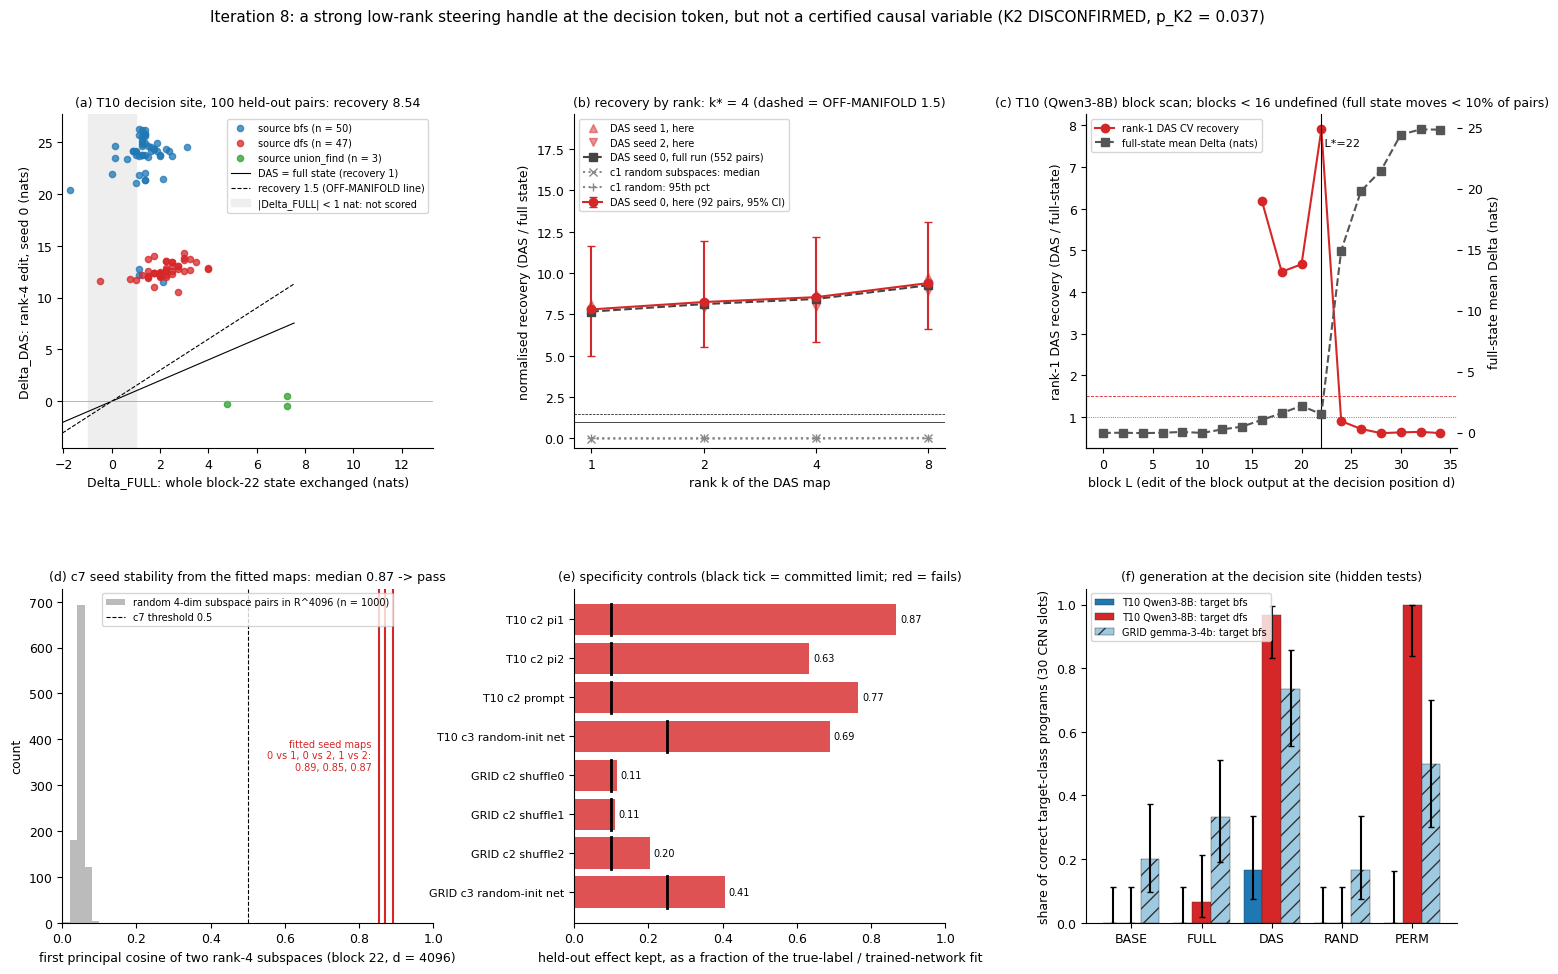

In [21]:
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})   # src/figures8.py style
COL = {"bfs": "#1f77b4", "dfs": "#d62728", "union_find": "#2ca02c"}

fig, axes = plt.subplots(2, 3, figsize=(18, 10.5))
fig.subplots_adjust(wspace=0.38, hspace=0.42)

# (a) per-pair effects: rank-k* DAS edit vs full-state exchange
ax = axes[0, 0]
dk = np.array([r["delta"] for r in tf_rows if r["fit"] == "seed0" and r["rank_k"] == kstar])
src_cls = [classes[cls[s]] for s, _ in held]
for c in classes:
    ix = [i for i, x in enumerate(src_cls) if x == c]
    if ix:
        ax.scatter(full_h["delta"][ix], dk[ix], s=20, alpha=0.75, color=COL[c], label=f"source {c} (n = {len(ix)})")
xs = np.linspace(min(full_h["delta"].min(), -1.0) - 0.3, full_h["delta"].max() + 0.3, 10)
ax.plot(xs, xs, "k-", lw=0.8, label="DAS = full state (recovery 1)")
ax.plot(xs, OFF_MANIFOLD * xs, "k--", lw=0.8, label=f"recovery {OFF_MANIFOLD} (OFF-MANIFOLD line)")
ax.axvspan(-1, 1, color="#eeeeee", zorder=0, label="|Delta_FULL| < 1 nat: not scored")
ax.axhline(0, color="#999999", lw=0.5)
ax.set_xlabel("Delta_FULL: whole block-22 state exchanged (nats)")
ax.set_ylabel(f"Delta_DAS: rank-{kstar} edit, seed 0 (nats)")
ax.set_title(f"(a) T10 decision site, {len(held)} held-out pairs: recovery {f2(main['recovery'])}", fontsize=9)
ax.set_xlim(xs[0], xs[-1] + 0.6 * (xs[-1] - xs[0]))          # notebook: room for the legend on the right
ax.legend(fontsize=7, loc="upper right")

# (b) held-out recovery by rank (src/figures8.py f2_rank, with this notebook's subset)
ax = axes[0, 1]
ks = list(RANKS)
rr = np.array([rec_rank[k]["recovery"] for k in ks], dtype=float)
lo = np.array([rec_rank[k]["ci95"][0] if rec_rank[k]["ci95"][0] is not None else rec_rank[k]["recovery"] for k in ks])
hi = np.array([rec_rank[k]["ci95"][1] if rec_rank[k]["ci95"][1] is not None else rec_rank[k]["recovery"] for k in ks])
ax.errorbar(ks, rr, yerr=[rr - lo, hi - rr], fmt="o-", color="#d62728", capsize=3,
            label=f"DAS seed 0, here ({main['n']} pairs, 95% CI)")
for sd, mk in ((1, "^"), (2, "v")):
    ax.plot(ks, [rec_rank[f"seed{sd}"][k]["recovery"] for k in ks], mk, color="#d62728", alpha=0.5, ms=6,
            label=f"DAS seed {sd}, here")
ax.plot(ks, [rep_rr[str(k)]["recovery"] for k in ks], "s--", color="#444444",
        label=f"DAS seed 0, full run ({rep_dec['main']['n']} pairs)")
ax.plot(ks, [rep_dec["c1"][str(k)]["median"] for k in ks], "x:", color="#888888", label="c1 random subspaces: median")
ax.plot(ks, [rep_dec["c1"][str(k)]["p95"] for k in ks], "+:", color="#888888", label="c1 random: 95th pct")
ax.axhline(1.0, color="k", lw=0.5)
ax.axhline(OFF_MANIFOLD, color="k", lw=0.5, ls="--")
ax.set_xscale("log", base=2)
ax.set_xticks(ks)
ax.set_xticklabels(ks)
ax.set_xlabel("rank k of the DAS map")
ax.set_ylabel("normalised recovery (DAS / full state)")
ax.set_title(f"(b) recovery by rank: k* = {kstar} (dashed = OFF-MANIFOLD 1.5)", fontsize=9)
ax.set_ylim(-0.6, 1.5 * hi.max())          # notebook: headroom so the legend clears the error bars
ax.legend(fontsize=7, loc="upper left")

# (c) block scan (src/figures8.py f1_scan, T10)
ax = axes[0, 2]
sc = {int(k): v for k, v in REP["scan_T10"].items()}
Ls = sorted(sc)
rec_s = [float(sc[l]["cv_median_recovery"]) if sc[l]["cv_median_recovery"] is not None else np.nan for l in Ls]
full_s = [sc[l]["full_state_mean_delta_held96"] for l in Ls]
ax.plot(Ls, rec_s, "o-", color="#d62728", label="rank-1 DAS CV recovery")
ax.axhline(1.0, color="#d62728", lw=0.6, ls=":")
ax.axhline(1.5, color="#d62728", lw=0.6, ls="--")
ax.set_xlabel("block L (edit of the block output at the decision position d)")
ax.set_ylabel("rank-1 DAS recovery (DAS / full-state)")
ax2 = ax.twinx()
ax2.plot(Ls, full_s, "s--", color="#555555", label="full-state mean Delta (nats)")
ax2.set_ylabel("full-state mean Delta (nats)")
ax.axvline(L, color="k", lw=0.8)
ax.text(L, np.nanmax(rec_s) * 0.95, f" L*={L}", fontsize=8)
first_def = min(l for l, v in zip(Ls, rec_s) if np.isfinite(v))
ax.set_title(f"(c) T10 (Qwen3-8B) block scan; blocks < {first_def} undefined (full state moves < 10% of pairs)",
             fontsize=9)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=7, loc="upper left")

# (d) c7: the seed maps vs random subspace pairs (first principal cosine)
ax = axes[1, 0]
ax.hist(rnd, bins=np.linspace(0, 1, 51), color="#bbbbbb", label=f"random {kstar}-dim subspace pairs in R^{D} (n = {len(rnd)})")
for c_ in cos:
    ax.axvline(c_, color="#d62728", lw=1.5)
ax.text(min(cos) - 0.02, ax.get_ylim()[1] * 0.5, "fitted seed maps\n0 vs 1, 0 vs 2, 1 vs 2:\n" + ", ".join(f"{c_:.2f}" for c_ in cos),
        fontsize=7, color="#d62728", ha="right", va="center")
ax.axvline(THRESH["c7_cos_min"], color="k", ls="--", lw=0.8, label="c7 threshold 0.5")
ax.set_xlim(0, 1)
ax.set_xlabel(f"first principal cosine of two rank-{kstar} subspaces (block 22, d = {D})")
ax.set_ylabel("count")
ax.set_title(f"(d) c7 seed stability from the fitted maps: median {c7['median_first_cosine']:.2f} -> "
             f"{'pass' if c7['pass'] else 'FAIL'}", fontsize=9)
ax.legend(fontsize=7, loc="upper center")

# (e) specificity controls that decide K2 (fraction of the true / trained effect kept)
ax = axes[1, 1]
rows = [(f"T10 c2 {n}", REP["dec_T10"]["c2"][n]["ratio_to_true_fit"], THRESH["c2_ratio_max"]) for n in ("pi1", "pi2", "prompt")]
rows.append(("T10 c3 random-init net", REP["rinit_T10"]["ratio"], THRESH["c3_ratio_max"]))
rows += [(f"GRID c2 {n}", REP["dec_GRID"]["c2"][n]["ratio_to_true_fit"], THRESH["c2_ratio_max"])
         for n in ("shuffle0", "shuffle1", "shuffle2")]
rows.append(("GRID c3 random-init net", REP["rinit_GRID"]["ratio"], THRESH["c3_ratio_max"]))
yy = np.arange(len(rows))[::-1]
ax.barh(yy, [r[1] for r in rows], color=["#d62728" if r[1] > r[2] else "#2ca02c" for r in rows], alpha=0.8)
for yi, r in zip(yy, rows):
    ax.plot([r[2], r[2]], [yi - 0.4, yi + 0.4], "k-", lw=2)
    ax.text(r[1] + 0.01, yi, f"{r[1]:.2f}", va="center", fontsize=7)
ax.set_yticks(yy)
ax.set_yticklabels([r[0] for r in rows], fontsize=8)
ax.set_xlim(0, 1)
ax.set_xlabel("held-out effect kept, as a fraction of the true-label / trained-network fit")
ax.set_title("(e) specificity controls (black tick = committed limit; red = fails)", fontsize=9)

# (f) generation: correct target-class programs by arm (src/figures8.py f4_generation)
ax = axes[1, 2]
arms_f = ["BASE", "FULL", "DAS", "RAND", "PERM"]
groups = [("gen_T10_dec", "bfs", "#1f77b4", None), ("gen_T10_dec", "dfs", "#d62728", None),
          ("gen_GRID_dec", "bfs", "#9ecae1", "//")]
xg = np.arange(len(arms_f))
w = 0.8 / len(groups)
for j, (key, c, colr, hatch) in enumerate(groups):
    v = res[key]["classes"][c]["arms"]
    sh = [v[a]["share"] if a in v else np.nan for a in arms_f]
    cis = [v[a]["wilson95"] if a in v else [np.nan, np.nan] for a in arms_f]
    lo_ = [max(0.0, s - c_[0]) if a in v else 0 for s, c_, a in zip(sh, cis, arms_f)]
    hi_ = [max(0.0, c_[1] - s) if a in v else 0 for s, c_, a in zip(sh, cis, arms_f)]
    ax.bar(xg + j * w, sh, w, yerr=[lo_, hi_], capsize=2, color=colr, hatch=hatch, edgecolor="#333333", lw=0.3,
           label=f"{'T10 Qwen3-8B' if 'T10' in key else 'GRID gemma-3-4b'}: target {c}")
ax.set_xticks(xg + w * (len(groups) - 1) / 2)
ax.set_xticklabels(arms_f)
ax.set_ylim(0, 1.05)
ax.set_ylabel("share of correct target-class programs (30 CRN slots)")
ax.set_title("(f) generation at the decision site (hidden tests)", fontsize=9)
ax.legend(fontsize=7, loc="upper left")

fig.suptitle("Iteration 8: a strong low-rank steering handle at the decision token, but not a certified causal "
             f"variable (K2 {K2['status']}, p_K2 = {K2['p_K2']:.3f})", fontsize=11)
plt.show()

In [22]:
# ---- summary: what this notebook computed vs what the full GPU run reported
rows = [
    ("CPU equivalence test (KV / band paths vs full recompute)", "PASS" if ok else "FAIL", "PASS"),
    (f"T10 decision-site TF recovery at k* (here {main['n']} pairs; run {rep_dec['main']['n']})",
     f"{f2(main['recovery'])} {ci(main['ci95'])}", f"{f2(rep_dec['main']['recovery'])} {ci(rep_dec['main']['ci95'])}"),
    ("k* / OFF-MANIFOLD flag", f"{kstar} / {off_manifold_flag}", f"{rep_dec['k_star']} / {rep_dec['off_manifold_flag']}"),
    ("mean Delta_DAS vs mean Delta_FULL at k* (nats)", f"{f2(main['mean_delta_edit'])} vs {f2(main['mean_delta_full'])}",
     f"{f2(rep_dec['main']['mean_delta_edit'])} vs {f2(rep_dec['main']['mean_delta_full'])}"),
    ("c7 seed stability, median first cosine (pass?)", f"{c7['median_first_cosine']:.3f} ({c7['pass']})",
     f"{rep_c7['median_first_cosine']:.3f} ({rep_c7['pass']})"),
    ("c2 label-control ratios pi1 / pi2 / prompt (limit 0.10)", "(stored)",
     " / ".join(f2(rep_dec["c2"][n]["ratio_to_true_fit"]) for n in ("pi1", "pi2", "prompt"))),
    ("c3 random-init ratio (limit 0.25)", "(stored)", f2(REP["rinit_T10"]["ratio"])),
    ("verdict T10-dec", verdicts["T10-dec"]["verdict"], REP["verdicts"]["T10-dec"]["verdict"]),
    ("verdict T10-band", verdicts["T10-band"]["verdict"], REP["verdicts"]["T10-band"]["verdict"]),
    ("verdict GRID-dec", verdicts["GRID-dec"]["verdict"], REP["verdicts"]["GRID-dec"]["verdict"]),
    ("K2 status (p_K2)", f"{K2['status']} ({K2['p_K2']:.3f})", f"{REP['K2']['status']} ({REP['K2']['p_K2']:.3f})"),
]
w0 = max(len(r[0]) for r in rows)
print(f"{'quantity':<{w0}} | {'this notebook':<26} | full run")
print("-" * (w0 + 52))
for name, here, stored in rows:
    print(f"{name:<{w0}} | {here:<26} | {stored}")
print(f"\nnotebook compute time (after installs): {time.time() - T0_NOTEBOOK:.1f}s")

quantity                                                     | this notebook              | full run
----------------------------------------------------------------------------------------------------------------
CPU equivalence test (KV / band paths vs full recompute)     | PASS                       | PASS
T10 decision-site TF recovery at k* (here 92 pairs; run 552) | 8.54 [5.83, 12.18]         | 8.43 [5.94, 11.30]
k* / OFF-MANIFOLD flag                                       | 4 / True                   | 4 / True
mean Delta_DAS vs mean Delta_FULL at k* (nats)               | 17.31 vs 2.03              | 17.37 vs 2.06
c7 seed stability, median first cosine (pass?)               | 0.869 (True)               | 0.869 (True)
c2 label-control ratios pi1 / pi2 / prompt (limit 0.10)      | (stored)                   | 0.87 / 0.63 / 0.77
c3 random-init ratio (limit 0.25)                            | (stored)                   | 0.69
verdict T10-dec                                           